<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridQSVMQNN_IoTAnomalyDetection_Deepa2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QSVM + QNN for IoT anomaly detection on UNSW-NB15: Deepa et al. step by step

This notebook re-implements, runs and checks the experiment of

> B. Deepa, M. Murugappan, G. Jashwanth Kumar and S. Iswariya, "A Hybrid Quantum Framework for Ultra-Secure Communication and Anomaly Detection in IoT Systems,"
> in M. Trabelsi et al. (eds.), *Proceedings of the 2nd Symposium on Smart, Sustainable, and Secure Internet of Things*, Lecture Notes in Electrical Engineering 1513, Springer, 2026, pp. 317-327. https://doi.org/10.1007/978-981-95-5136-1_30

**What the paper does.** It builds a *quantum-enhanced hybrid anomaly detector* for IoT traffic from two quantum models run in parallel: a **quantum support vector machine (QSVM)**, a quantum kernel `|<phi(x)|phi(y)>|^2` fed to a classical SVM, and a **quantum neural network (QNN)**, a variational quantum circuit trained with COBYLA and a cross-entropy loss. Both use a `ZZFeatureMap` on 4 qubits. Their class probabilities are averaged with equal weights (**soft voting**). The data is UNSW-NB15, cleaned by removing duplicates, scaled with Min-Max and reduced to the most informative features with **mutual information**. The paper compares classical SVM and ANN, QSVM alone, QNN alone and the hybrid (its Table 1: hybrid 96.0 % accuracy, 95.4 % precision, 94.9 % recall, 95.1 % F1). The title also promises "ultra-secure communication" (quantum key distribution, post-quantum cryptography); the paper discusses these only in its related-work section and runs **no** experiment on them, so nothing there can be reproduced.

**What this notebook does.**

1. downloads the official UNSW-NB15 training and testing partitions from a Hugging Face mirror, removes duplicates and shows the real data;
2. Min-Max scales the flows, ranks the features by mutual information and keeps one feature per qubit (4), all fitted on the training partition only;
3. trains the QSVM (exact quantum kernel + SVM), the QNN (`VQC`, ZZ feature map + `RealAmplitudes`, COBYLA, cross-entropy) and their **soft-voting hybrid**, plus classical SVM, ANN and random-forest baselines on the *same* 4 inputs (and on all features);
4. draws every quantum circuit that is executed;
5. evaluates under the paper's two protocols: the **official 175,341 / 82,332 train/test split**, repeated over several seeds, and **stratified 5-fold cross-validation**;
6. prints a claim-by-claim comparison with the paper's Table 1 and its qualitative claims.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. No GPU and no IBM account are needed. `FAST_MODE = True` runs the whole notebook in about 10 minutes; `FAST_MODE = False` uses larger samples, three seeds, 5-fold cross-validation and a bigger COBYLA budget (see the last cell for the wall-clock time of the run that produced the saved outputs). Quantum simulation limits the models to hundreds of flows, so the numbers are *not* directly comparable to a classical model trained on 175,341 flows.

**Data access.** The mirror used here is public. If you point `HF_REPO_MAIN` at a gated Hugging Face repository, add your own token in Colab under *Settings -> Secrets* as `HF_TOKEN` (locally: environment variable `HF_TOKEN`); the notebook reads it from there and never asks you to type it into a cell.

## The paper in one page

**Problem.** Detect attacks (binary: normal vs attack) in IoT network traffic with quantum machine learning that fits simulators and near-term hardware.

**Method.** Preprocessing (duplicate removal, Min-Max to [0, 1], mutual-information feature selection) -> `ZZFeatureMap` encoding (2 repetitions, 4 qubits) -> **QSVM** (quantum kernel, SVM with Lagrange multipliers in [0, 0.5]) and **QNN** (variational circuit, COBYLA, cross-entropy) in parallel -> **soft vote** with weights 0.5 / 0.5 -> "Normal" or "Attack".

**Data.** UNSW-NB15, "around 2.5 million records with 49 features" (sic: the public data set has 2,540,044 records in its raw CSVs and 257,673 in the official partitions), split as the data set's predefined 175,341-record training and 82,332-record testing partitions; "five-fold cross-validation over multiple runs" is also mentioned. Simulation with Qiskit Aer, 4 qubits, learning rate 0.05, COBYLA.

**Claims we can test.**

| Id | Claim | Where |
|---|---|---|
| C1 | Hybrid QSVM+QNN: accuracy 96.0, precision 95.4, recall 94.9, F1 95.1 (%) | Table 1, Sec. 4.2 |
| C2 | The other four rows: SVM 89.2 / 88.4 / 87.6 / 88.0, ANN 90.5 / 89.7 / 89.1 / 89.4, QSVM 93.1 / 92.4 / 91.8 / 92.1, QNN 94.2 / 93.7 / 92.8 / 93.2 (accuracy / precision / recall / F1) | Table 1 |
| C3 | The ranking SVM < ANN < QSVM < QNN < Hybrid ("a clear progression from classical to quantum to hybrid") | Sec. 4.2 |
| C4 | The hybrid beats both standalone quantum models and both classical models | Sec. 4.2, Conclusion |
| C5 | The circuit has 4 qubits, "a depth of 2" (read as 2 feature-map repetitions) and 30 gate operations | Sec. 4, Fig. 3 |
| C6 | QSVM is better at low-frequency attacks such as U2R and **Probe**; QNN is better at large-scale attacks such as **DoS** and R2L | Abstract, Sec. 1 |
| C7 | Five-fold cross-validation gives consistent performance | Sec. 4 |

Paper numbers were transcribed from the PDF text of Table 1. The QKD / post-quantum-cryptography part of the title has no experiment and is not testable.

### What follows the paper and what had to be chosen

The paper fixes the pipeline and the model families. It reports no sample sizes, no feature count (only that the "highest MI scores are retained"), no ansatz, no shot count and no iteration budget, and publishes no code. Each choice made here is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | UNSW-NB15 | Official training partition (175,341 flows) and testing partition (82,332 flows) from the Hugging Face mirror `research-simulation26/unsw-nb15-parquet` (fallback `Mireu-Lab/UNSW-NB15`, file names swapped) |
| Duplicates | removed | removed from both partitions (`DROP_DUPLICATES = True`). This shrinks the partitions to about 107,700 / 55,900 flows, which contradicts the 175,341 / 82,332 the paper quotes after cleaning; the effect is discussed in the critical-reading section |
| Scaling | Min-Max to [0, 1] | Min-Max fitted on a class-balanced pool of training-partition flows; test values clipped to [0, 1]. No `log1p` (`LOG_TRANSFORM = False`) |
| Categorical columns | not mentioned | `proto`, `service`, `state` one-hot encoded (8 most frequent values each), then Min-Max like the rest |
| Feature selection | mutual information, "highest scores retained", count not given | `mutual_info_classif` on the pool, top 4 = one feature per qubit |
| Encoding | `ZZFeatureMap`, 2 repetitions, 4 qubits | `zz_feature_map(4, reps=2, entanglement="linear")`; features multiplied by a **bandwidth** chosen on a validation split (1 is the paper's literal [0, 1] encoding) |
| QSVM | quantum kernel + SVM, alpha in [0, 0.5] | Exact fidelity kernel (`FidelityStatevectorKernel`), `SVC(kernel="precomputed")`; `C` chosen from {0.5, 1, 10} on the validation split (0.5 is the paper's alpha bound); probabilities by Platt scaling for the vote |
| QNN | VQC, `RY` rotations (Eq. 6) or ZZ map (Sec. 3.2), COBYLA, cross-entropy, learning rate 0.05 | Qiskit `VQC`: ZZ feature map (Sec. 3.2, Fig. 3) + `real_amplitudes(4, reps=2)`, COBYLA, cross-entropy, Aer sampler. The learning rate has no meaning for COBYLA and is unused |
| Ensemble | average of the class probabilities, equal weights | the same, threshold 0.5 |
| Baselines | classical SVM, ANN (numbers cited from unrelated papers) | `SVC(rbf)` and `MLPClassifier(16, 8)` on the same 4 inputs and on all features, plus a random forest |
| Training size | not reported | class-balanced sample of the training partition (`N_TRAIN`), random sample of the testing partition at its natural class mix (`N_TEST`) |
| Protocols | official 68/32 split; five-fold CV | both: split repeated over seeds, and stratified k-fold CV on a sample of the training partition |
| Metrics | accuracy, precision, recall, F1 (averaging not stated) | accuracy and attack-class precision/recall/F1 (attack = positive); macro averages also printed |
| Tolerance | - | a paper value is *reproduced* when within 2 points, *exceeded* / *not reached* otherwise |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc pyarrow huggingface_hub
print("setup done (if Colab asks you to restart the session, do so and run all cells again)")

setup done (if Colab asks you to restart the session, do so and run all cells again)


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo (about 10 min); False: larger samples, 3 seeds, 5-fold CV (see last cell for the time)

SEED      = 42
SEEDS     = [42] if FAST_MODE else [42, 43, 44]     # seeds of the official-split study (Section 8)
N_QUBITS  = 4               # the paper: "a 4-qubit system" (Fig. 3)

# Preprocessing / training sizes (the paper reports none of these)
N_FIT_POOL = 2000 if FAST_MODE else 4000            # CHOICE: class-balanced training-partition flows used to fit Min-Max and the MI ranking
N_TRAIN, N_TEST = (90, 300) if FAST_MODE else (300, 1000)   # CHOICE: quantum-simulation sizes
VQC_MAXITER = 30 if FAST_MODE else 60               # CHOICE: COBYLA budget (function evaluations); the paper gives none
SHOTS       = 1024                                  # CHOICE
VAL_FRAC    = 0.3                                   # CHOICE: share of the training sample held out to choose bandwidth and C

# QSVM hyper-parameters, chosen on the validation split of the training sample only
BANDWIDTHS = [1.0, 2.0, 3.14159265, 6.2831853]      # CHOICE: angle scale; 1 = the paper's literal [0, 1] encoding
C_GRID     = [0.5, 1.0, 10.0]                       # CHOICE: 0.5 = the paper's alpha bound (Eq. 5)

# Five-fold cross-validation (paper Sec. 4)
RUN_CV   = True
N_FOLDS  = 3 if FAST_MODE else 5
N_CV     = 120 if FAST_MODE else 300                # CHOICE: sample of the training partition (natural class mix)

DROP_DUPLICATES = True      # the paper removes duplicate records (see the table above for the consequences)
LOG_TRANSFORM   = False     # False = Min-Max only, as in the paper; True = log1p first
DATA_DIR   = "unsw_nb15"    # downloaded files are cached here
LOCAL_TRAIN = ""            # optional: path to your own copy of the official training set (csv or parquet)
LOCAL_TEST  = ""            # optional: path to your own copy of the official testing set
IBM_TOKEN   = ""            # not needed: everything here runs on simulators
NOTEBOOK_T0 = __import__("time").time()
print("FAST_MODE =", FAST_MODE, "| train/test flows", N_TRAIN, N_TEST, "| seeds", SEEDS, "| CV folds", N_FOLDS)

FAST_MODE = False | train/test flows 300 1000 | seeds [42, 43, 44] | CV folds 5


In [3]:
import os, time, warnings, math, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

warnings.filterwarnings("ignore")

import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC

import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
np.random.seed(SEED)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

# Hugging Face token: only needed if you point the loader at a gated repository (the default mirror is public).
# Never type a token into a cell; on Colab store it under Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. Data: UNSW-NB15

The paper uses **UNSW-NB15** (Moustafa and Slay, MilCIS 2015, UNSW Canberra), generated in the Cyber Range Lab of the Australian Centre for Cyber Security with the IXIA PerfectStorm tool. Each row is one network flow described by 42 features (durations, packets and bytes per direction, TTLs, loads, jitter, TCP window and round-trip times, connection-count statistics, protocol, service and state) and two labels: `label` (0 = normal, 1 = attack) and `attack_cat` with one of nine attack categories (**Fuzzers, Analysis, Backdoor, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms**).

The data set's authors publish an official **training partition** (175,341 flows) and **testing partition** (82,332 flows); the paper quotes exactly these two sizes, so they are used here, training on the first and testing on the second. They come from the public Hugging Face mirror `research-simulation26/unsw-nb15-parquet`. If that mirror is unreachable the code falls back to `Mireu-Lab/UNSW-NB15`, whose `train.csv` and `test.csv` carry the *swapped* contents, and swaps them back.

A note on the paper's data description: "around 2.5 million records with 49 features" describes the raw capture files (2,540,044 records, 49 columns including identifiers and both labels). The official partitions have 257,673 records and 45 columns; the mirror drops a few identifier columns.

In [4]:
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback: train.csv holds the official TESTING set, test.csv the official TRAINING set

RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    # Common column names/labels across the two mirrors
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    # Return (official training partition, official testing partition) as DataFrames
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)    # official training set
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)   # official testing set
        return tidy(read_any(a)), tidy(read_any(b))

t0 = time.time()
raw_train, raw_test = load_unsw()
print(f"raw official partitions: training {raw_train.shape}, testing {raw_test.shape} ({time.time() - t0:.0f} s)")
assert len(raw_train) > len(raw_test), "partitions look swapped"

loaded from research-simulation26/unsw-nb15-parquet


raw official partitions: training (175341, 44), testing (82332, 44) (3 s)


## 2. Data preprocessing (paper Sec. 3.1)

The paper's steps, in its order:

1. **Remove duplicate records** (`DROP_DUPLICATES = True`). The public CSVs have no IP addresses, ports or timestamps, so identical rows are often *different* flows (thousands of identical DNS probes, for instance); removing them deletes about 39 % of the training flows and most of the "Generic" category, which changes the class mix of the official partitions. The paper does this and also quotes the full partition sizes, which cannot both be true; this notebook follows the *text* and applies the removal to both partitions (a label-independent cleaning step, so it leaks nothing). Set the flag to `False` to see the difference.
2. **Min-Max normalisation** to [0, 1], Eq. (1): $X' = (X - X_{min})/(X_{max} - X_{min})$. The minimum and maximum come from a class-balanced pool of *training-partition* flows (`N_FIT_POOL`); test values outside the pool's range are clipped to [0, 1].
3. **Mutual-information feature selection**, Eq. (2): $I(X,Y)=\sum_x\sum_y p(x,y)\log\frac{p(x,y)}{p(x)p(y)}$ between every feature and the attack/normal label, estimated with scikit-learn's `mutual_info_classif` on the same pool. The paper keeps "the highest MI scores" but not how many; one feature per qubit means the **top 4**.

Housekeeping the paper does not mention (each a `# CHOICE`): `stcpb` and `dtcpb` (randomly chosen initial TCP sequence numbers, identifier-like noise) are dropped; `proto`, `service` and `state` are one-hot encoded (8 most frequent values each, the rest pooled); infinities and missing values are dropped (none occur).

Everything is fitted on **training-partition flows only**; the testing partition is transformed with the fitted objects.

In [5]:
DROP_COLS = ["stcpb", "dtcpb"]                     # CHOICE: random TCP sequence bases
CAT_COLS  = ["proto", "service", "state"]
ATTACKS   = ["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]
CATS      = ["Normal"] + ATTACKS

def clean(df, name):
    n0 = len(df)
    df = df.drop(columns=DROP_COLS)
    num = [c for c in df.columns if c not in CAT_COLS + ["attack_cat"]]
    df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]] = df[["is_ftp_login", "ct_ftp_cmd", "ct_flw_http_mthd"]].fillna(0)
    df = df.replace([np.inf, -np.inf], np.nan).dropna()
    n1 = len(df)
    if DROP_DUPLICATES:
        df = df.drop_duplicates()
    df = df.reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    print(f"{name}: {n0:,} flows -> {n1:,} without missing/infinite values -> {len(df):,} kept (DROP_DUPLICATES = {DROP_DUPLICATES})")
    return df

train_part = clean(raw_train, "training partition")
test_part  = clean(raw_test, "testing partition")
NUM_COLS = [c for c in train_part.columns if c not in CAT_COLS + ["attack_cat", "label"]]
FEATS = NUM_COLS + CAT_COLS
print(len(NUM_COLS), "numeric +", len(CAT_COLS), "categorical features")
print("training partition after cleaning:", train_part["attack_cat"].value_counts().to_dict())
print("testing partition after cleaning :", test_part["attack_cat"].value_counts().to_dict())

training partition: 175,341 flows -> 175,341 without missing/infinite values -> 107,740 kept (DROP_DUPLICATES = True)


testing partition: 82,332 flows -> 82,332 without missing/infinite values -> 55,945 kept (DROP_DUPLICATES = True)
37 numeric + 3 categorical features
training partition after cleaning: {'Normal': 51890, 'Exploits': 19844, 'Fuzzers': 16150, 'Reconnaissance': 7522, 'Generic': 4181, 'DoS': 3806, 'Analysis': 1594, 'Backdoor': 1535, 'Shellcode': 1091, 'Worms': 127}
testing partition after cleaning : {'Normal': 34206, 'Exploits': 7609, 'Fuzzers': 4838, 'Generic': 3657, 'Reconnaissance': 2703, 'DoS': 1718, 'Analysis': 446, 'Shellcode': 378, 'Backdoor': 346, 'Worms': 44}


In [6]:
def log1p_clip(X):
    return np.log1p(np.clip(X, 0, None))

def make_encoder():
    num = FunctionTransformer(log1p_clip, feature_names_out="one-to-one") if LOG_TRANSFORM else "passthrough"
    return ColumnTransformer([
        ("num", num, NUM_COLS),
        ("cat", OneHotEncoder(max_categories=8, handle_unknown="infrequent_if_exist", sparse_output=False), CAT_COLS)])

def draw_sample(seed):
    # pool: class-balanced training-partition flows that fit Min-Max and the MI ranking
    # tr  : class-balanced training sample the quantum models are trained on (training partition)
    # te  : random sample of the testing partition at its natural class mix
    g = train_part.groupby("label", group_keys=False)
    pool = g.sample(n=N_FIT_POOL // 2, random_state=seed + 1000)
    tr = g.sample(n=N_TRAIN // 2, random_state=seed).sample(frac=1, random_state=seed).reset_index(drop=True)
    te = test_part.sample(n=N_TEST, random_state=seed).reset_index(drop=True)
    return pool, tr, te

def prepare(pool, frames, seed, k=None):
    # Fit encoder + Min-Max + MI ranking on the pool; return all encoded features (F) and the k selected ones (X) for each frame
    k = k or N_QUBITS
    pipe = Pipeline([("enc", make_encoder()), ("mm", MinMaxScaler())]).fit(pool[FEATS])
    names = [n.split("__", 1)[1] for n in pipe.named_steps["enc"].get_feature_names_out()]
    mi = mutual_info_classif(pipe.transform(pool[FEATS]), pool["label"], random_state=seed)
    sel = np.argsort(mi)[::-1][:k]
    F = [np.clip(pipe.transform(f[FEATS]), 0, 1) for f in frames]
    return dict(pipe=pipe, names=names, mi=mi, sel=sel, F=F, X=[f[:, sel] for f in F])

pool, tr_df, te_df = draw_sample(SEED)
prep = prepare(pool, [tr_df, te_df], SEED)
X_train, X_test = prep["X"]; F_train, F_test = prep["F"]
y_train, y_test = tr_df["label"].to_numpy(), te_df["label"].to_numpy()
sel_names = [prep["names"][i] for i in prep["sel"]]
print(f"pool {len(pool)} flows | train sample {X_train.shape} (balanced: {np.bincount(y_train).tolist()}) | test sample {X_test.shape} (natural mix: {np.bincount(y_test).tolist()})")
print(f"{len(prep['names'])} encoded features; top-{N_QUBITS} by mutual information (one per qubit):")
for i in prep["sel"]:
    print(f"   qubit {list(prep['sel']).index(i)}: {prep['names'][i]:22s} MI = {prep['mi'][i]:.3f}")

pool 4000 flows | train sample (300, 4) (balanced: [150, 150]) | test sample (1000, 4) (natural mix: [589, 411])
58 encoded features; top-4 by mutual information (one per qubit):
   qubit 0: sbytes                 MI = 0.394
   qubit 1: sttl                   MI = 0.392
   qubit 2: dttl                   MI = 0.388
   qubit 3: ct_state_ttl           MI = 0.381


## Dataset Exploration and Visualisation

Everything below shows the **real UNSW-NB15 flows** and their ground-truth labels: the shape, the feature names and the original label values; the class distributions of both official partitions and of the samples used here; the mutual-information ranking (the paper's Fig. 2); and 2-D scatter plots of the real training flows coloured by their true class. The scatter plots come in pairs: the first two PCA coordinates of the 4 selected features (PCA fitted on the training sample), and the same points rescaled to angles in [0, pi]; then the first two selected features themselves, and finally a PCA of *all* encoded features for context. The binary training sample is coloured by attack category (multiclass labels kept) and by the binary label.

In [7]:
print("official training partition (raw)  :", raw_train.shape, "| after cleaning:", train_part.shape)
print("official testing partition (raw)   :", raw_test.shape, "| after cleaning:", test_part.shape)
print(f"\nfeatures used ({len(FEATS)}): numeric ({len(NUM_COLS)}) = {NUM_COLS}\n  categorical ({len(CAT_COLS)}) = {CAT_COLS}")
print("\noriginal labels")
print("  label (0 normal / 1 attack), raw training :", raw_train["label"].value_counts().to_dict(), "| raw testing:", raw_test["label"].value_counts().to_dict())
print("  attack_cat, raw training :", raw_train["attack_cat"].value_counts().to_dict())
print("  attack_cat, raw testing  :", raw_test["attack_cat"].value_counts().to_dict())
print("\nafter duplicate removal")
print("  label, training :", train_part["label"].value_counts().to_dict(), "| testing:", test_part["label"].value_counts().to_dict())
print("\nsample used for the official-split study (seed %d)" % SEED)
print("  train attack_cat:", tr_df["attack_cat"].value_counts().to_dict())
print("  test  attack_cat:", te_df["attack_cat"].value_counts().to_dict())
display(train_part[FEATS + ["attack_cat", "label"]].head(5))
display(train_part[NUM_COLS].describe().T[["mean", "std", "min", "max"]].head(12))

official training partition (raw)  : (175341, 44) | after cleaning: (107740, 42)
official testing partition (raw)   : (82332, 44) | after cleaning: (55945, 42)

features used (40): numeric (37) = ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sintpkt', 'dintpkt', 'sjit', 'djit', 'swin', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
  categorical (3) = ['proto', 'service', 'state']

original labels
  label (0 normal / 1 attack), raw training : {1: 119341, 0: 56000} | raw testing: {1: 45332, 0: 37000}
  attack_cat, raw training : {'Normal': 56000, 'Generic': 40000, 'Exploits': 33393, 'Fuzzers': 18184, 'DoS': 12264, 'Reconnaissance': 10491, 'Analysis': 2000, 'Backdoor': 1746, 'Shellcode': 11

,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sintpkt,dintpkt,sjit,djit,swin,dwin,tcprtt,synack,ackdat,smeansz,dmeansz,trans_depth,res_bdy_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,proto,service,state,attack_cat,label
0,0.121478,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,tcp,-,FIN,Normal,0
1,0.649902,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,tcp,-,FIN,Normal,0
2,1.623129,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,tcp,-,FIN,Normal,0
3,1.681642,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,tcp,ftp,FIN,Normal,0
4,0.449454,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,tcp,-,FIN,Normal,0


,mean,std,min,max
dur,1.355982e+00,5.521568e+00,0.0,5.999999e+01
spkts,3.019046e+01,1.734179e+02,1.0,9.616000e+03
dpkts,3.005909e+01,1.365459e+02,0.0,1.097400e+04
sbytes,1.382541e+04,2.226347e+05,28.0,1.296523e+07
dbytes,2.373248e+04,1.786208e+05,0.0,1.465555e+07
rate,3.869093e+04,1.166318e+05,0.0,1.000000e+06
sttl,1.430522e+02,1.077762e+02,0.0,2.550000e+02
dttl,1.216000e+02,1.160158e+02,0.0,2.540000e+02
sload,4.968117e+07,2.114064e+08,0.0,5.988000e+09
dload,1.089236e+06,3.013781e+06,0.0,2.242273e+07


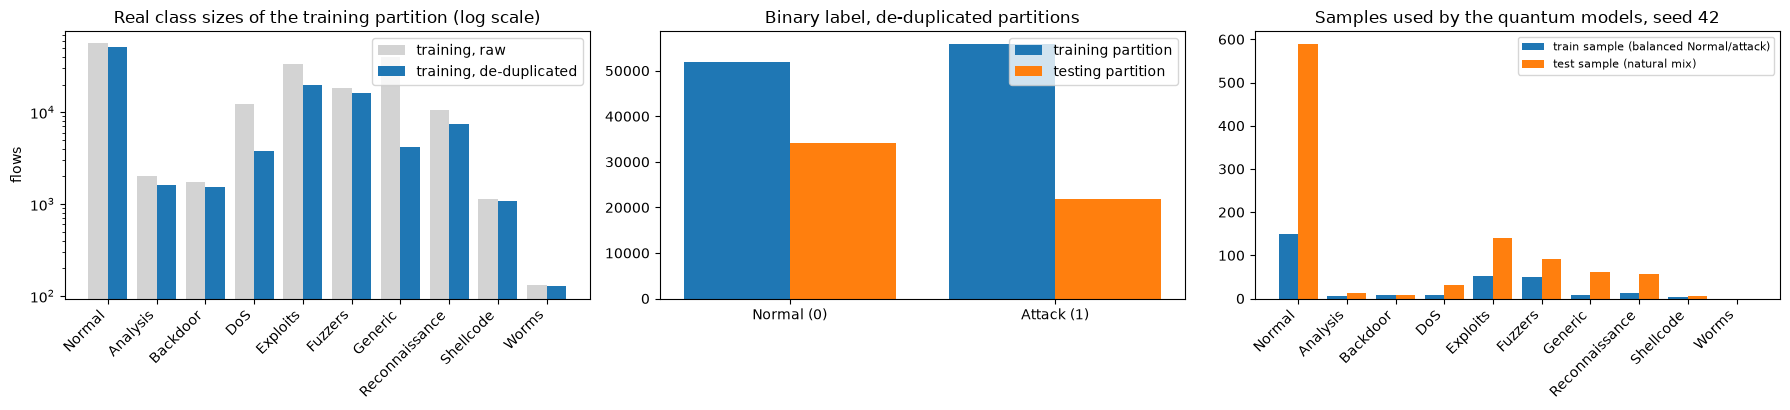

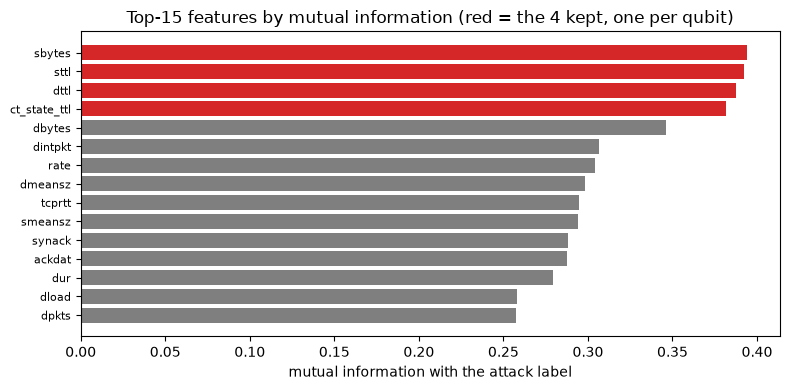

In [8]:
PAL = dict(zip(CATS, plt.cm.tab10(np.arange(10))))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.2))
w = 0.4
cnt_raw = raw_train["attack_cat"].value_counts().reindex(CATS)
cnt_tr = train_part["attack_cat"].value_counts().reindex(CATS); cnt_te = test_part["attack_cat"].value_counts().reindex(CATS)
ax[0].bar(np.arange(10) - w / 2, cnt_raw.values, w, label="training, raw", color="lightgray")
ax[0].bar(np.arange(10) + w / 2, cnt_tr.values, w, label="training, de-duplicated", color="tab:blue")
ax[0].set_yscale("log"); ax[0].set_xticks(range(10)); ax[0].set_xticklabels(CATS, rotation=45, ha="right"); ax[0].legend()
ax[0].set_title("Real class sizes of the training partition (log scale)"); ax[0].set_ylabel("flows")
bin_tr = train_part["label"].value_counts().sort_index(); bin_te = test_part["label"].value_counts().sort_index()
ax[1].bar(np.arange(2) - w / 2, bin_tr.values, w, label="training partition", color="tab:blue")
ax[1].bar(np.arange(2) + w / 2, bin_te.values, w, label="testing partition", color="tab:orange")
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["Normal (0)", "Attack (1)"]); ax[1].legend(); ax[1].set_title("Binary label, de-duplicated partitions")
s_tr = tr_df["attack_cat"].value_counts().reindex(CATS).fillna(0); s_te = te_df["attack_cat"].value_counts().reindex(CATS).fillna(0)
ax[2].bar(np.arange(10) - w / 2, s_tr.values, w, label="train sample (balanced Normal/attack)", color="tab:blue")
ax[2].bar(np.arange(10) + w / 2, s_te.values, w, label="test sample (natural mix)", color="tab:orange")
ax[2].set_xticks(range(10)); ax[2].set_xticklabels(CATS, rotation=45, ha="right"); ax[2].legend(fontsize=8); ax[2].set_title("Samples used by the quantum models, seed %d" % SEED)
plt.tight_layout(); plt.show()

# the paper's Fig. 2: mutual-information scores
order = np.argsort(prep["mi"])[::-1][:15]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(range(len(order))[::-1], prep["mi"][order], color=["tab:red" if i in prep["sel"] else "tab:gray" for i in order])
ax.set_yticks(range(len(order))[::-1]); ax.set_yticklabels([prep["names"][i] for i in order], fontsize=8)
ax.set_xlabel("mutual information with the attack label"); ax.set_title("Top-15 features by mutual information (red = the %d kept, one per qubit)" % N_QUBITS)
plt.tight_layout(); plt.show()

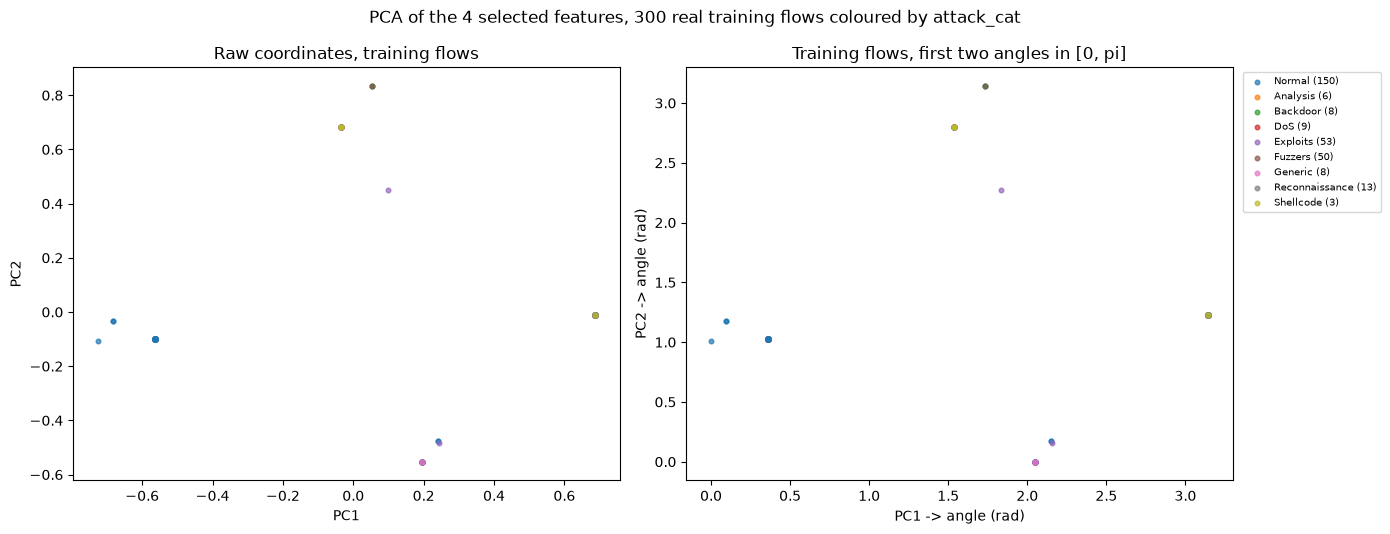

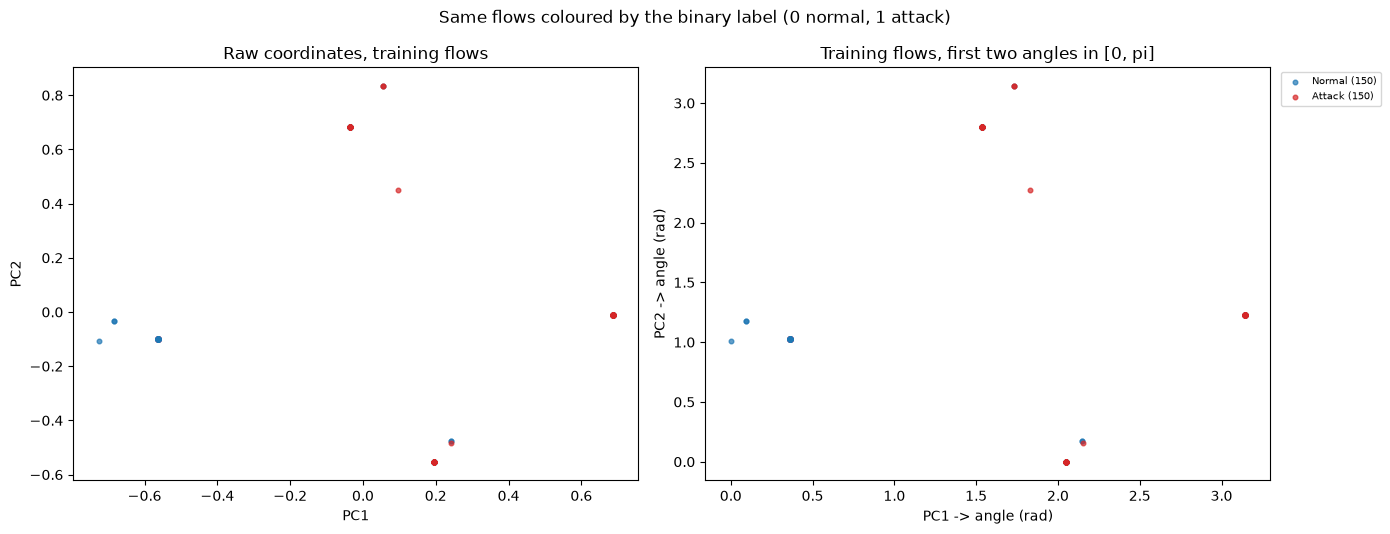

variance explained by the PCA of the 4 selected features: [0.647 0.318 0.03  0.005]
distinct positions in the 4-feature space: 167 for 300 real flows (features such as the TTLs and ct_state_ttl take only a few values, so many flows overlap exactly)
   sbytes         distinct values in the training sample: 150
   sttl           distinct values in the training sample: 5
   dttl           distinct values in the training sample: 4
   ct_state_ttl   distinct values in the training sample: 5


In [9]:
def scatter_pair(Z, A, labels, names, palette, title, xl=("PC1", "PC2"), al=("PC1 -> angle (rad)", "PC2 -> angle (rad)")):
    # left: raw coordinates, right: the same flows as angles in [0, pi]; every point is one real flow
    fig, ax = plt.subplots(1, 2, figsize=(14, 5.4))
    for k, name in enumerate(names):
        m = labels == k
        if m.sum() == 0: continue
        ax[0].scatter(Z[m, 0], Z[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
        ax[1].scatter(A[m, 0], A[m, 1], s=11, alpha=.7, color=palette[name], label=f"{name} ({m.sum()})")
    ax[0].set_xlabel(xl[0]); ax[0].set_ylabel(xl[1]); ax[0].set_title("Raw coordinates, training flows")
    ax[1].set_xlabel(al[0]); ax[1].set_ylabel(al[1]); ax[1].set_title("Training flows, first two angles in [0, pi]")
    ax[1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1.0))
    fig.suptitle(title); plt.tight_layout(); plt.show()

BPAL = {"Normal": "tab:blue", "Attack": "tab:red"}
cat_idx = tr_df["attack_cat"].map({c: i for i, c in enumerate(CATS)}).to_numpy()

# (1) PCA of the 4 selected features (fitted on the training sample), then the same coordinates scaled to [0, pi]
pca4 = PCA(n_components=N_QUBITS, random_state=SEED).fit(X_train)
Z4 = pca4.transform(X_train); A4 = MinMaxScaler((0, np.pi)).fit_transform(Z4)
scatter_pair(Z4, A4, cat_idx, CATS, PAL, "PCA of the %d selected features, %d real training flows coloured by attack_cat" % (N_QUBITS, len(tr_df)))
scatter_pair(Z4, A4, y_train, ["Normal", "Attack"], BPAL, "Same flows coloured by the binary label (0 normal, 1 attack)")
print("variance explained by the PCA of the 4 selected features:", np.round(pca4.explained_variance_ratio_, 3))
print(f"distinct positions in the 4-feature space: {len(np.unique(X_train.round(6), axis=0))} for {len(X_train)} real flows (features such as the TTLs and ct_state_ttl take only a few values, so many flows overlap exactly)")
for n_, j in zip(sel_names, range(N_QUBITS)):
    print(f"   {n_:14s} distinct values in the training sample: {len(np.unique(X_train[:, j].round(6)))}")

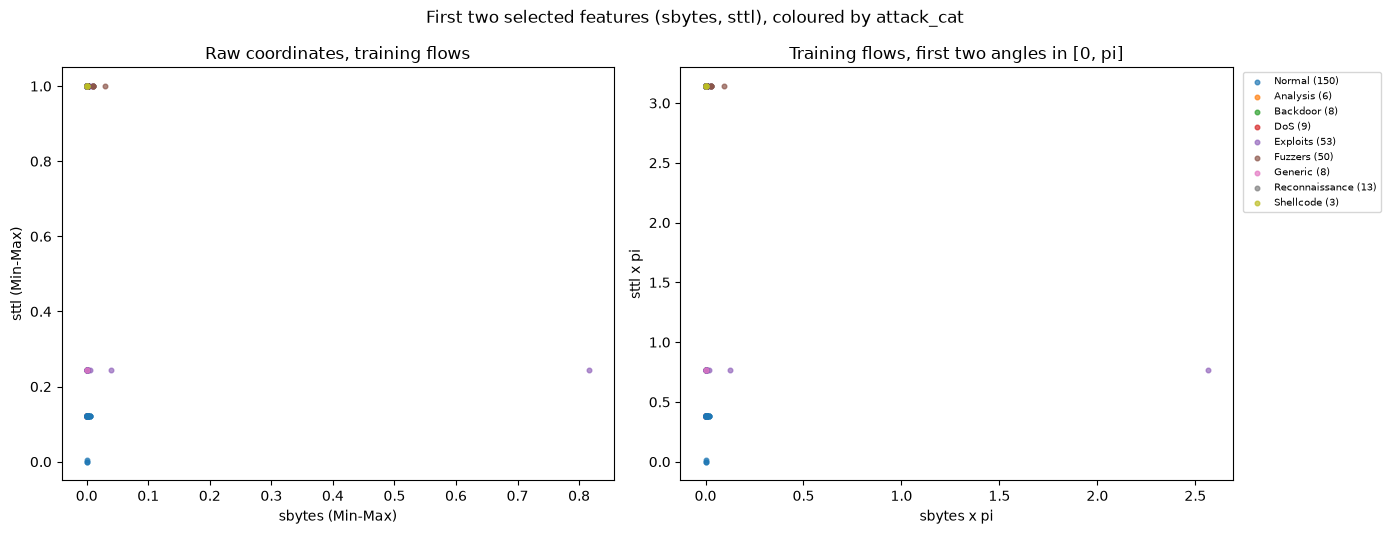

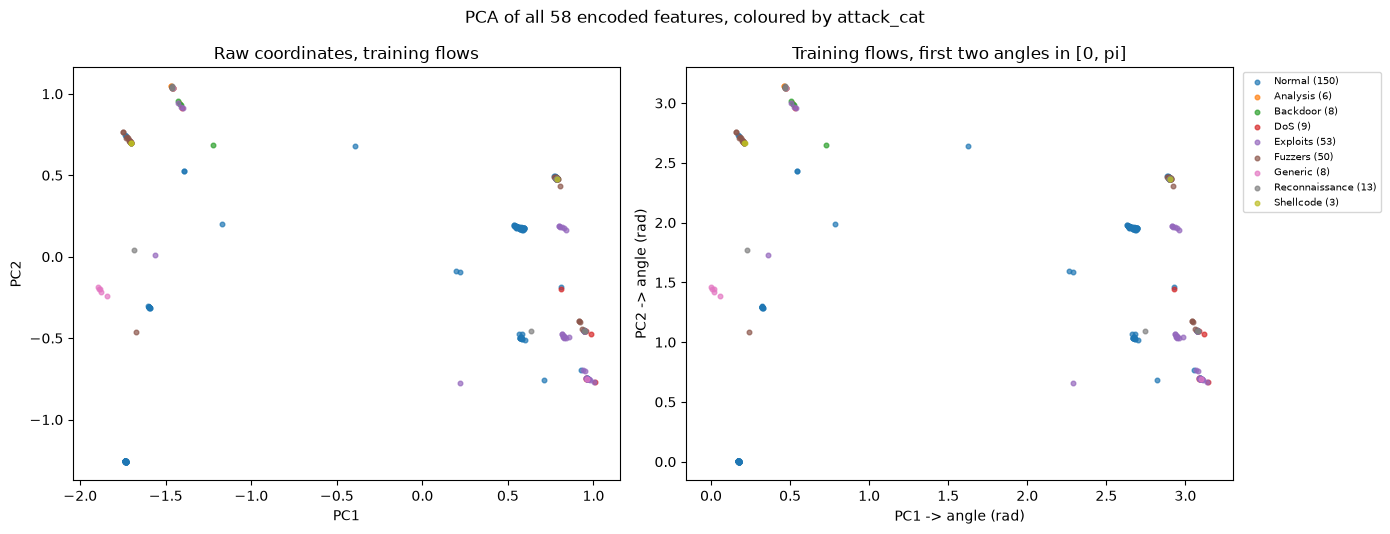

variance explained by the 2 leading components of all features: [0.472 0.156]


In [10]:
# (2) the first two selected features themselves (what qubits 0 and 1 receive), in [0, 1] and as angles in [0, pi]
scatter_pair(X_train, np.pi * X_train, cat_idx, CATS, PAL,
             "First two selected features (%s, %s), coloured by attack_cat" % tuple(sel_names[:2]),
             xl=(sel_names[0] + " (Min-Max)", sel_names[1] + " (Min-Max)"), al=(sel_names[0] + " x pi", sel_names[1] + " x pi"))

# (3) context: PCA of ALL encoded features of the same flows
pcaF = PCA(n_components=2, random_state=SEED).fit(F_train)
ZF = pcaF.transform(F_train); AF = MinMaxScaler((0, np.pi)).fit_transform(ZF)
scatter_pair(ZF, AF, cat_idx, CATS, PAL, "PCA of all %d encoded features, coloured by attack_cat" % F_train.shape[1])
print("variance explained by the 2 leading components of all features:", np.round(pcaF.explained_variance_ratio_, 3))

## 3. Quantum encoding: the ZZ feature map (paper Sec. 3.2, Eq. 3)

A feature map writes a classical vector $x$ into a quantum state $|\phi(x)\rangle = U_{enc}(x)|0\rangle^{\otimes 4}$. The paper chooses Qiskit's `ZZFeatureMap` "because of its pairwise feature representation and entangling architecture" (and because "preliminary trials showed superior performance", with no numbers). Each repetition applies Hadamards, a phase rotation $e^{ix_jZ_j}$ per qubit and a two-qubit phase $e^{i(\pi-x_j)(\pi-x_k)Z_jZ_k}$ per neighbouring pair (Eq. 3 abbreviates this). The paper's Fig. 3 states 2 repetitions on 4 qubits; the pairing pattern is not given and `linear` (neighbours only) is used (`# CHOICE`). The circuit is drawn in the circuit section further down, together with the QNN and kernel circuits.

Features are multiplied by a **bandwidth** $b$ before encoding, $x \mapsto b\,x$. With $b = 1$ the features Min-Max-scaled to [0, 1] occupy only about a third of a full rotation; the bandwidth is chosen on a validation split of the training sample (kernel quality only, never on the test flows) and the QNN reuses it, so both models see the same encoding.

## 4. Quantum Support Vector Machine (paper Sec. 3.3.1, Eqs. 4-5)

The kernel measures how close two encoded flows are, $K(x_i,x_j)=|\langle\phi(x_i)|\phi(x_j)\rangle|^2$ (Eq. 4), and a classical SVM finds the maximum-margin hyperplane in that feature space with the decision function $f(x)=\mathrm{sign}\big(\sum_i\alpha_i y_i K(x_i,x)+b\big)$ (Eq. 5), $\alpha_i\in[0,C]$. The paper writes that $\alpha_i$ "varies from 0 to 0.5", which is the box constraint $C = 0.5$; it is therefore the first value of the `C` grid. Nothing is optimised on the quantum side. `FidelityStatevectorKernel` computes the overlaps exactly from statevectors (a noiseless stand-in for the paper's Aer simulation). For the soft vote the SVM must output probabilities; scikit-learn's Platt scaling (`probability=True`) provides them.

The cell below defines the kernel, the validation search and the final fit, and cross-checks a block of the kernel matrix computed by hand from `Statevector` objects.

validation F1 per (bandwidth, C): {(1.0, 0.5): 0.928, (1.0, 1.0): 0.905, (1.0, 10.0): 0.905, (2.0, 0.5): 0.928, (2.0, 1.0): 0.905, (2.0, 10.0): 0.905, (3.14, 0.5): 0.907, (3.14, 1.0): 0.917, (3.14, 10.0): 0.917, (6.28, 0.5): 0.918, (6.28, 1.0): 0.907, (6.28, 10.0): 0.905}
chosen bandwidth 1.00, C 0.5 | 79 support vectors of 300 | fit + predict 16.7 s
QSVM on the test sample: accuracy 0.7520, F1 0.7674
hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel: True


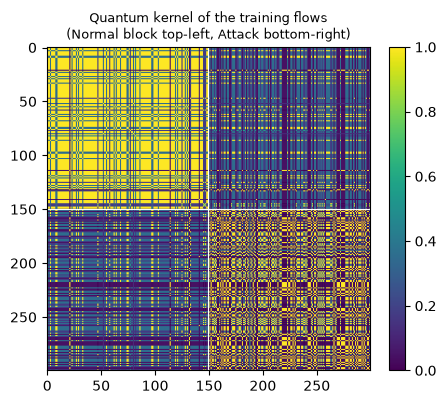

In [11]:
FM = zz_feature_map(N_QUBITS, reps=2, entanglement="linear")      # CHOICE: linear entanglement; reps = 2 as in the paper's Fig. 3
KERNEL = FidelityStatevectorKernel(feature_map=FM)

def kernel(A, B, bw):
    # |<phi(a)|phi(b)>|^2 for angle-scaled rows; B=None gives the symmetric training matrix
    return KERNEL.evaluate(bw * A) if B is None else KERNEL.evaluate(bw * A, bw * B)

def run_qsvm(Xtr, ytr, Xte, seed):
    # 1) bandwidth and C on a validation split of the training sample (test flows untouched)
    Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=VAL_FRAC, stratify=ytr, random_state=seed)
    val = {}
    for bw in BANDWIDTHS:
        Ka, Kv = kernel(Xa, None, bw), kernel(Xv, Xa, bw)
        for C in C_GRID:
            val[(bw, C)] = f1_score(yv, SVC(kernel="precomputed", C=C).fit(Ka, ya).predict(Kv))
    bw, C = max(val, key=val.get)                        # ties keep the first option
    # 2) final fit on the whole training sample, probabilities for the vote
    t0 = time.time()
    Kt, Ke = kernel(Xtr, None, bw), kernel(Xte, Xtr, bw)
    svm = SVC(kernel="precomputed", C=C, probability=True, random_state=seed).fit(Kt, ytr)
    return dict(p=svm.predict_proba(Ke)[:, 1], bw=bw, C=C, val=val, K=Kt, time=time.time() - t0, svm=svm)

qs = run_qsvm(X_train, y_train, X_test, SEED)
print("validation F1 per (bandwidth, C):", {(round(k[0], 2), k[1]): round(v, 3) for k, v in qs["val"].items()})
print(f"chosen bandwidth {qs['bw']:.2f}, C {qs['C']} | {qs['svm'].support_.size} support vectors of {len(y_train)} | fit + predict {qs['time']:.1f} s")
print(f"QSVM on the test sample: accuracy {accuracy_score(y_test, qs['p'] >= .5):.4f}, F1 {f1_score(y_test, qs['p'] >= .5):.4f}")

# cross-check: the same kernel entries from statevectors by hand
bw = qs["bw"]
states = [Statevector(FM.assign_parameters(bw * x)) for x in X_train[:20]]
K_hand = np.abs(np.array([[a.inner(b) for b in states] for a in states])) ** 2
print("hand-computed |<phi(a)|phi(b)>|^2 matches FidelityStatevectorKernel:", np.allclose(K_hand, qs["K"][:20, :20], atol=1e-6))

order = np.argsort(y_train, kind="stable")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(qs["K"][order][:, order], cmap="viridis", vmin=0, vmax=1)
ax.axhline((y_train == 0).sum() - .5, color="w", lw=.8); ax.axvline((y_train == 0).sum() - .5, color="w", lw=.8)
ax.set_title("Quantum kernel of the training flows\n(Normal block top-left, Attack bottom-right)", fontsize=9)
plt.colorbar(im, fraction=0.046); plt.show()

## 5. Quantum Neural Network (paper Sec. 3.3.2, Eqs. 6-7)

The QNN is a variational quantum circuit: the data are encoded, a trainable circuit $U_\theta$ follows, and an observable is measured, $\hat y=\langle 0|U_{enc}^\dagger U_\theta^\dagger M U_\theta U_{enc}|0\rangle$ (Eq. 7), read as the probability of "attack". The parameters are trained with **COBYLA** on a **cross-entropy** loss. The paper is inconsistent about the encoding: Eq. 6 writes $R_Y(x)$ rotations, but Sec. 3.2 says the ZZ feature map serves "QSVM and QNN" and Fig. 3 shows one 4-qubit circuit, so the ZZ map is used (`# CHOICE`). The ansatz is not given; `real_amplitudes(4, reps=2)` (12 trainable angles) is used (`# CHOICE`). Qiskit's `VQC` implements exactly this recipe: it measures every qubit and reads the class from the parity of the measured bit string, with the Aer sampler as the simulator. The "learning rate 0.05" of the paper belongs to gradient optimisers and has no meaning for COBYLA.

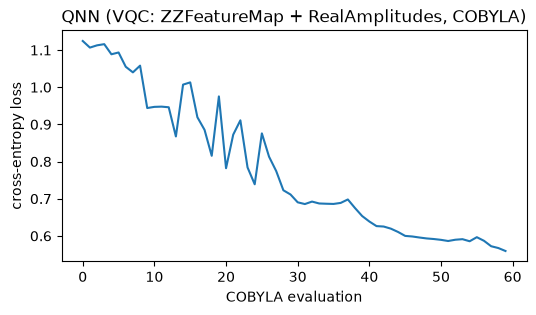

QNN trained+predicted in 448 s (60 COBYLA evaluations, final loss 0.559)
QNN on the test sample: accuracy 0.7200, F1 0.6419


In [12]:
def make_live_plot(title, every=5):
    # Return (callback, history). The callback records the loss and redraws the curve every few evaluations when LIVE is on.
    history = []
    def callback(weights, loss):
        history.append(loss)
        if LIVE[0] and len(history) % every == 0:
            clear_output(wait=True)
            plt.figure(figsize=(6, 3)); plt.plot(history); plt.xlabel("COBYLA evaluation")
            plt.ylabel("cross-entropy loss"); plt.title(title); plt.show()
    return callback, history
LIVE = [True]

def run_qnn(Xtr, ytr, Xte, bw, seed, maxiter, title="QNN (VQC: ZZFeatureMap + RealAmplitudes, COBYLA)"):
    algorithm_globals.random_seed = seed
    cb, hist = make_live_plot(title)
    model = VQC(feature_map=zz_feature_map(N_QUBITS, reps=2, entanglement="linear"), ansatz=real_amplitudes(N_QUBITS, reps=2),
                optimizer=COBYLA(maxiter=maxiter), callback=cb, sampler=AerSampler(default_shots=SHOTS, seed=seed))
    t0 = time.time(); model.fit(bw * Xtr, ytr); p = model.predict_proba(bw * Xte)[:, 1]
    return dict(p=p, hist=hist, time=time.time() - t0, model=model, bw=bw)

qn = run_qnn(X_train, y_train, X_test, qs["bw"], SEED, VQC_MAXITER)
print(f"QNN trained+predicted in {qn['time']:.0f} s ({len(qn['hist'])} COBYLA evaluations, final loss {qn['hist'][-1]:.3f})")
print(f"QNN on the test sample: accuracy {accuracy_score(y_test, qn['p'] >= .5):.4f}, F1 {f1_score(y_test, qn['p'] >= .5):.4f}")

## 6. Integration and inference: soft voting (paper Sec. 3.3.3)

Both models run in parallel on the same encoded flows. The ensemble layer averages their class probabilities with equal weights (0.5 each) and outputs "Attack" when the averaged attack probability is at least 0.5, otherwise "Normal". The cell also shows the vote on a few test flows.

In [13]:
def soft_vote(p_qsvm, p_qnn, w=0.5):
    return w * p_qsvm + (1 - w) * p_qnn            # the paper: equal weights 0.5 / 0.5

p_hybrid = soft_vote(qs["p"], qn["p"])
print(f"hybrid on the test sample: accuracy {accuracy_score(y_test, p_hybrid >= .5):.4f}, F1 {f1_score(y_test, p_hybrid >= .5):.4f}")
rows = []
for i in range(8):
    rows.append({"flow": i, "true category": te_df.loc[i, "attack_cat"], "p(attack) QSVM": round(qs["p"][i], 2), "p(attack) QNN": round(qn["p"][i], 2),
                 "hybrid": round(p_hybrid[i], 2), "decision": "ALERT: attack" if p_hybrid[i] >= .5 else "normal"})
display(pd.DataFrame(rows))

hybrid on the test sample: accuracy 0.7320, F1 0.7532


,flow,true category,p(attack) QSVM,p(attack) QNN,hybrid,decision
0,0,Generic,0.83,0.70,0.76,ALERT: attack
1,1,Exploits,0.83,0.75,0.79,ALERT: attack
2,2,Normal,0.26,0.77,0.52,ALERT: attack
3,3,Normal,0.01,0.07,0.04,normal
4,4,Normal,0.79,0.51,0.65,ALERT: attack
5,5,Normal,0.01,0.08,0.04,normal
6,6,Normal,0.83,0.46,0.64,ALERT: attack
7,7,Fuzzers,0.83,0.71,0.77,ALERT: attack


## 7. Classical baselines

The paper compares with a classical SVM and an ANN whose numbers it takes from two earlier papers by one of its authors (EEG emotion recognition and hearing-loss detection, its refs. 16-17), not from runs on UNSW-NB15 with the same inputs. Here both are trained on **exactly the inputs the quantum models see** (the 4 mutual-information features) and, for context, on **all encoded features**: `SVC(kernel="rbf", C=1)`, a small `MLPClassifier` (two hidden layers of 16 and 8 neurons, the "ANN") and a random forest. The gap between the 4-feature and all-feature rows measures what the qubit budget costs, independent of whether the model is quantum.

In [14]:
def run_classical(X4tr, ytr, X4te, Ftr, Fte, seed):
    # attack probabilities of the classical baselines on the 4 selected features and on all encoded features
    P = {}
    for tag, (A, B) in {"": (X4tr, X4te), " (all)": (Ftr, Fte)}.items():
        P["SVM" + tag] = SVC(kernel="rbf", C=1.0, probability=True, random_state=seed).fit(A, ytr).predict_proba(B)[:, 1]
        P["ANN" + tag] = MLPClassifier(hidden_layer_sizes=(16, 8), max_iter=1000, random_state=seed).fit(A, ytr).predict_proba(B)[:, 1]
        P["RF" + tag]  = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=2).fit(A, ytr).predict_proba(B)[:, 1]
    return P

def metrics(y, p, thr=0.5):
    yp = (np.asarray(p) >= thr).astype(int)
    return {"accuracy": 100 * accuracy_score(y, yp), "precision": 100 * precision_score(y, yp, zero_division=0),
            "recall": 100 * recall_score(y, yp, zero_division=0), "F1": 100 * f1_score(y, yp, zero_division=0),
            "macro precision": 100 * precision_score(y, yp, average="macro", zero_division=0),
            "macro recall": 100 * recall_score(y, yp, average="macro", zero_division=0),
            "macro F1": 100 * f1_score(y, yp, average="macro", zero_division=0)}

t0 = time.time()
P_cl = run_classical(X_train, y_train, X_test, F_train, F_test, SEED)
t_cl = time.time() - t0
RESA = {SEED: dict(y=y_test, cat=te_df["attack_cat"].to_numpy(), bw=qs["bw"], C=qs["C"],
                   P={**P_cl, "QSVM": qs["p"], "QNN": qn["p"], "Hybrid": p_hybrid}, t_qsvm=qs["time"], t_qnn=qn["time"], hist=qn["hist"])}
for k, v in P_cl.items():
    print(f"{k:11s} accuracy {100 * accuracy_score(y_test, v >= .5):6.2f} | F1 {100 * f1_score(y_test, v >= .5):6.2f}")
print(f"classical baselines took {t_cl:.0f} s")

SVM         accuracy  75.30 | F1  76.85
ANN         accuracy  72.60 | F1  74.95
RF          accuracy  81.20 | F1  79.02
SVM (all)   accuracy  77.10 | F1  78.04
ANN (all)   accuracy  79.40 | F1  78.32
RF (all)    accuracy  79.70 | F1  79.56
classical baselines took 8 s


## Quantum Circuit Architecture

This section draws the circuits that the cells above actually build and run, with qubit count, depth and trainable-parameter count for each: the ZZ feature map (shared by both models), the QNN as executed (feature map + ansatz + measurement of every qubit), the same circuit with one real flow and the trained weights bound, and the QSVM compute-uncompute circuit whose all-zero probability is the kernel entry. The paper draws one circuit (its Fig. 3: 4 qubits, "depth 2", 30 gate operations); the details it omits are listed at the end of the section.

ZZFeatureMap as a library object: depth 19 | repetitions 2 | entanglement linear
Feature map ZZFeatureMap(4, reps=2, linear): 4 qubits | depth 19 (decomposed) | 4 parameters (data inputs) | gate operations 34 {'u': 22, 'cx': 12}


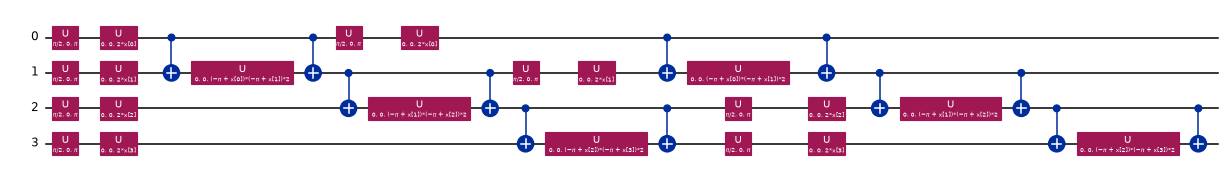

In [15]:
def flat_of(qc):
    try:
        return qc.decompose(reps=3)
    except Exception:
        return qc

def draw(qc, scale=0.5, decompose=True):
    c = qc.decompose() if decompose else qc
    return c.draw("mpl", fold=-1 if c.depth() <= 32 else 32, scale=scale)

def describe(name, qc, extra=""):
    flat = flat_of(qc)
    ops = {k: v for k, v in flat.count_ops().items() if k != "barrier"}
    n_gates = sum(v for k, v in ops.items() if k not in ("measure",))
    print(f"{name}: {qc.num_qubits} qubits | depth {flat.depth()} (decomposed) | {qc.num_parameters} parameters {extra}| gate operations {n_gates} {ops}")
    return flat.depth(), n_gates

print("ZZFeatureMap as a library object: depth", FM.depth(), "| repetitions 2 | entanglement linear")
d_fm, g_fm = describe("Feature map ZZFeatureMap(4, reps=2, linear)", FM, "(data inputs) ")
display(draw(FM, 0.55))

QNN circuit (ZZFeatureMap + RealAmplitudes + measurement): 4 qubits | depth 28 (decomposed) | 16 parameters (4 input angles + 12 trainable weights) | gate operations 52 {'u': 34, 'cx': 18, 'measure': 4}
trainable parameters: 12 (real_amplitudes, reps=2: 3 layers x 4 RY angles)


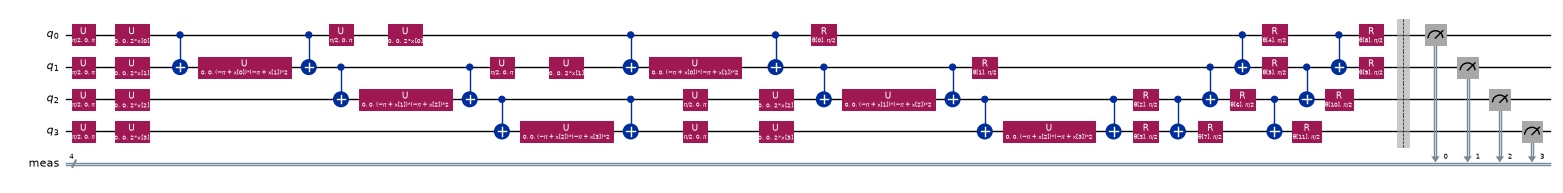

In [16]:
# The QNN exactly as the sampler runs it: feature map + ansatz + measurement of every qubit
vqc_model = qn["model"]
exec_circ = vqc_model.neural_network.circuit.copy(); exec_circ.measure_all()
n_in, n_w = len(vqc_model.feature_map.parameters), len(vqc_model.weights)
d_q, g_q = describe("QNN circuit (ZZFeatureMap + RealAmplitudes + measurement)", exec_circ, f"({n_in} input angles + {n_w} trainable weights) ")
print(f"trainable parameters: {n_w} (real_amplitudes, reps=2: 3 layers x 4 RY angles)")
display(draw(exec_circ, 0.5))

flow 0 of the test sample (true category Generic): angles [0.0, 1.0, 0.0, 0.33]


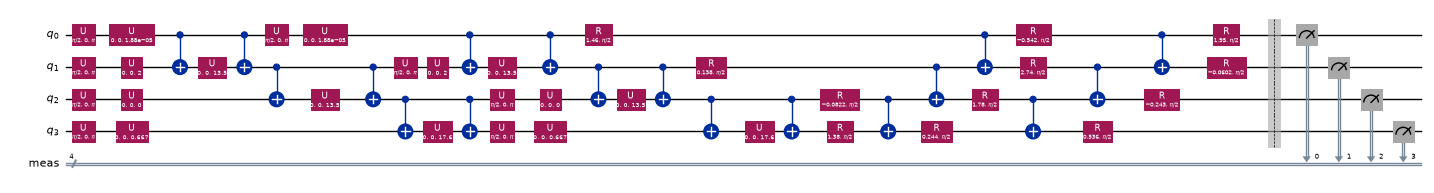

In [17]:
# The same circuit with one real test flow and the trained COBYLA weights bound: every gate now has a numeric angle
bound = vqc_model.neural_network.circuit.assign_parameters(
    {**dict(zip(vqc_model.feature_map.parameters, qs["bw"] * X_test[0])), **dict(zip(vqc_model.ansatz.parameters, vqc_model.weights))})
bound.measure_all()
print(f"flow 0 of the test sample (true category {te_df.loc[0, 'attack_cat']}): angles {np.round(qs['bw'] * X_test[0], 2).tolist()}")
display(draw(bound, 0.5))

QSVM kernel circuit U(b)^dagger U(a) + measurement: 4 qubits | depth 39 (decomposed) | 0 parameters (no trainable parameters) | gate operations 68 {'u': 44, 'cx': 24, 'measure': 4}
P(0000) = 0.304418 equals the kernel entry 0.304418 (asserted); on hardware it is estimated from shots


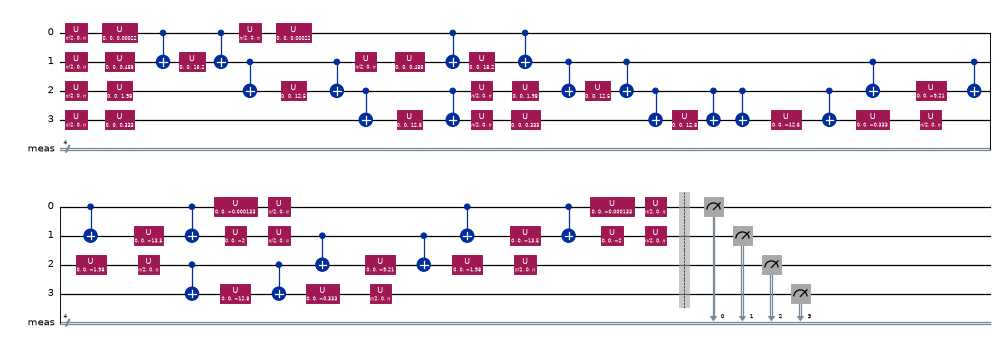

In [18]:
# QSVM: compute-uncompute circuit U(b)^dagger U(a) for two real training flows; P(0000) is the kernel entry
a, b = qs["bw"] * X_train[0], qs["bw"] * X_train[1]
fid = FM.assign_parameters(a).compose(FM.assign_parameters(b).inverse())
p_zero = abs(Statevector(fid).data[0]) ** 2
k_lib = KERNEL.evaluate(np.vstack([a, b]))[0, 1]
assert np.isclose(p_zero, k_lib, atol=1e-8), (p_zero, k_lib)
fid_m = fid.copy(); fid_m.measure_all()
d_k, g_k = describe("QSVM kernel circuit U(b)^dagger U(a) + measurement", fid_m, "(no trainable parameters) ")
print(f"P(0000) = {p_zero:.6f} equals the kernel entry {k_lib:.6f} (asserted); on hardware it is estimated from shots")
display(draw(fid_m, 0.45))

In [19]:
# Compare with the paper's Fig. 3 description: 4 qubits, "depth of 2", 30 gate operations
print(f"paper (Sec. 4, Fig. 3): 4 qubits, depth 2, 30 gates | here, feature map alone: {FM.num_qubits} qubits, 2 repetitions, "
      f"{g_fm} gate operations (22 single-qubit u + 12 cx after decomposition; 14 p + 12 cx + 8 h before), depth {d_fm}")

paper (Sec. 4, Fig. 3): 4 qubits, depth 2, 30 gates | here, feature map alone: 4 qubits, 2 repetitions, 34 gate operations (22 single-qubit u + 12 cx after decomposition; 14 p + 12 cx + 8 h before), depth 19


**Assumptions where the paper omits circuit details.**

- *Feature map:* 2 repetitions on 4 qubits are stated; `linear` entanglement (pairs 0-1, 1-2, 2-3) is assumed. The paper's "30 gate operations" cannot be matched exactly (34 after decomposition, 34 as `h`/`p`/`cx` instructions: 8 `h`, 14 `p`, 12 `cx`); with `full` entanglement the count is 52. "Depth of 2" is read as 2 repetitions: the decomposed depth is 19.
- *QNN encoding:* the ZZ feature map (Sec. 3.2, Fig. 3), not the plain $R_Y$ encoding of Eq. 6.
- *QNN ansatz:* not specified; `real_amplitudes(4, reps=2)`, i.e. $R_Y$ layers with a linear chain of CNOTs, 12 trainable angles.
- *Measurement:* every qubit is measured and the class is the parity of the bit string (the `VQC` read-out); the paper's observable $M$ is not specified.
- *Simulator:* `qiskit_aer` `SamplerV2` with 1024 shots for the QNN and exact statevectors for the QSVM kernel; no noise model, since the paper reports none.

## 8. Results on the official split (paper Table 1)

The remaining seeds of the official-split study run first (each seed draws a new training sample, test sample and feature-selection pool, retunes the QSVM and retrains the QNN). With `FAST_MODE = True` there is a single seed. The table then shows mean and standard deviation over seeds for every model, next to the paper's Table 1. Precision, recall and F1 treat **attack as the positive class**; macro-averaged values are printed as well because the paper does not say which averaging it used (note that its accuracy of 96.0 % exceeds its recall of 94.9 %, so it is not a support-weighted average).

In [20]:
def run_seed(seed):
    pool_s, tr_s, te_s = draw_sample(seed)
    pr = prepare(pool_s, [tr_s, te_s], seed)
    (Xa, Xb), (Fa, Fb) = pr["X"], pr["F"]
    ya, yb = tr_s["label"].to_numpy(), te_s["label"].to_numpy()
    q1 = run_qsvm(Xa, ya, Xb, seed)
    q2 = run_qnn(Xa, ya, Xb, q1["bw"], seed, VQC_MAXITER)
    P = run_classical(Xa, ya, Xb, Fa, Fb, seed)
    P.update({"QSVM": q1["p"], "QNN": q2["p"], "Hybrid": soft_vote(q1["p"], q2["p"])})
    sel_n = [pr["names"][i] for i in pr["sel"]]
    return dict(y=yb, cat=te_s["attack_cat"].to_numpy(), bw=q1["bw"], C=q1["C"], P=P, t_qsvm=q1["time"], t_qnn=q2["time"], hist=q2["hist"], sel=sel_n)

RESA[SEED]["sel"] = sel_names
LIVE[0] = False
for s in SEEDS:
    if s not in RESA:
        t0 = time.time(); RESA[s] = run_seed(s)
        print(f"seed {s}: bandwidth {RESA[s]['bw']:.2f}, C {RESA[s]['C']}, features {RESA[s]['sel']}, QNN {RESA[s]['t_qnn']:.0f} s (total {time.time() - t0:.0f} s)", flush=True)
LIVE[0] = True

MODELS_Q  = ["SVM", "ANN", "QSVM", "QNN", "Hybrid"]                 # the five rows of the paper's Table 1 (classical ones on the same 4 inputs)
MODELS_X  = ["RF", "SVM (all)", "ANN (all)", "RF (all)"]            # extras
PAPER = {"SVM": (89.2, 88.4, 87.6, 88.0), "ANN": (90.5, 89.7, 89.1, 89.4), "QSVM": (93.1, 92.4, 91.8, 92.1),
         "QNN": (94.2, 93.7, 92.8, 93.2), "Hybrid": (96.0, 95.4, 94.9, 95.1)}
METRIC_COLS = ["accuracy", "precision", "recall", "F1"]

per_seed = pd.DataFrame([{"seed": s, "model": m, **metrics(r["y"], r["P"][m])} for s, r in RESA.items() for m in MODELS_Q + MODELS_X])
meanA = per_seed.groupby("model")[METRIC_COLS + ["macro precision", "macro recall", "macro F1"]].mean().reindex(MODELS_Q + MODELS_X)
stdA  = per_seed.groupby("model")[METRIC_COLS].std(ddof=0).reindex(MODELS_Q + MODELS_X)
shown = meanA[METRIC_COLS].round(1).astype(str) + " +/- " + stdA.round(1).astype(str)
print(f"Official split: test sample of {N_TEST} flows from the de-duplicated testing partition, {len(SEEDS)} seed(s); mean +/- std over seeds (attack = positive)")
display(shown)
print("macro-averaged (mean over seeds):")
display(meanA[["macro precision", "macro recall", "macro F1"]].round(1))

seed 43: bandwidth 1.00, C 0.5, features ['sbytes', 'sttl', 'ct_state_ttl', 'dttl'], QNN 478 s (total 511 s)


seed 44: bandwidth 2.00, C 0.5, features ['sbytes', 'sttl', 'dttl', 'ct_state_ttl'], QNN 475 s (total 508 s)


Official split: test sample of 1000 flows from the de-duplicated testing partition, 3 seed(s); mean +/- std over seeds (attack = positive)


,accuracy,precision,recall,F1
model,,,,
SVM,73.7 +/- 1.3,60.2 +/- 1.8,99.7 +/- 0.1,75.0 +/- 1.4
ANN,71.9 +/- 1.9,58.6 +/- 1.9,99.5 +/- 0.2,73.7 +/- 1.6
QSVM,73.4 +/- 1.7,59.9 +/- 2.0,99.3 +/- 0.3,74.7 +/- 1.6
QNN,72.4 +/- 2.8,61.9 +/- 4.8,86.1 +/- 17.7,70.6 +/- 4.9
Hybrid,72.9 +/- 0.9,59.5 +/- 1.1,99.2 +/- 0.4,74.4 +/- 1.0
RF,78.4 +/- 3.0,67.7 +/- 4.6,88.1 +/- 1.6,76.5 +/- 2.7
SVM (all),75.6 +/- 1.4,62.1 +/- 1.8,98.6 +/- 0.8,76.2 +/- 1.4
ANN (all),78.3 +/- 1.0,66.4 +/- 2.3,92.1 +/- 3.3,77.1 +/- 0.9
RF (all),77.8 +/- 1.8,64.9 +/- 2.5,96.0 +/- 0.4,77.4 +/- 1.9


macro-averaged (mean over seeds):


,macro precision,macro recall,macro F1
model,,,
SVM,79.9,78.2,73.7
ANN,79.0,76.6,71.7
QSVM,79.6,77.9,73.3
QNN,76.2,75.0,71.9
Hybrid,79.3,77.4,72.8
RF,79.0,80.1,78.3
SVM (all),80.3,79.5,75.5
ANN (all),79.8,80.7,78.3
RF (all),80.5,80.9,77.8


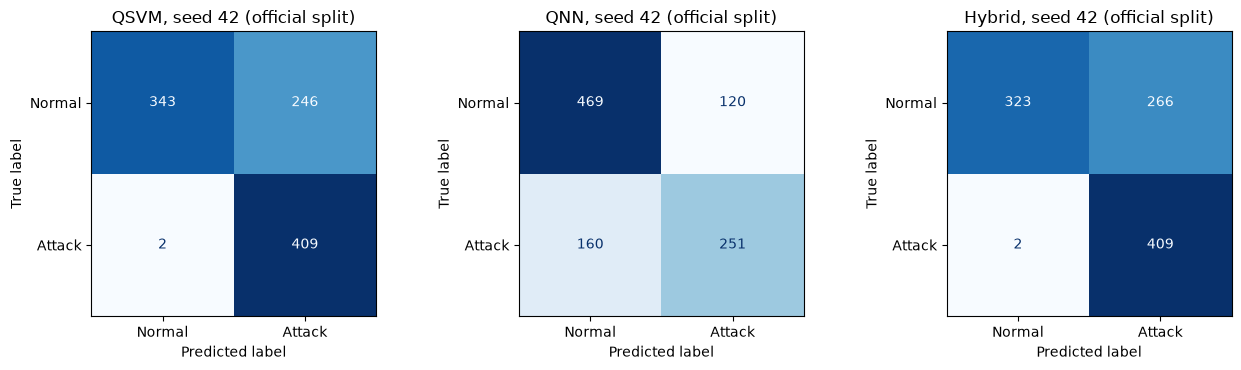

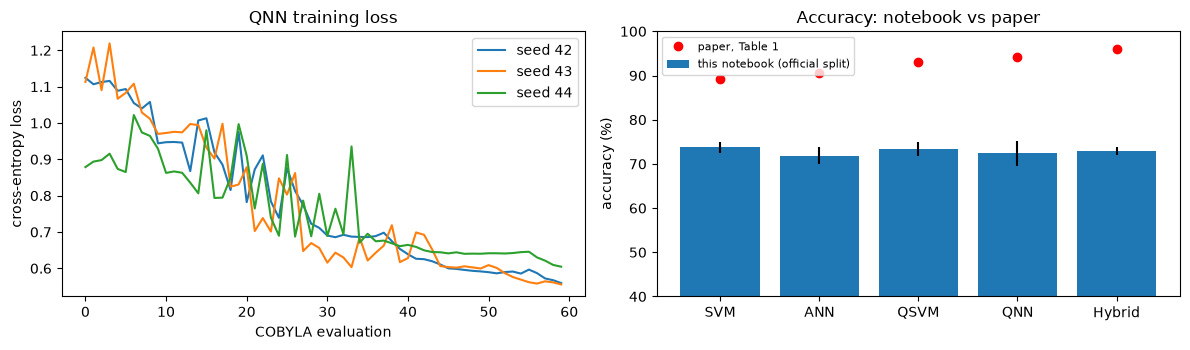

In [21]:
y0 = RESA[SEED]["y"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a_, m in zip(ax, ["QSVM", "QNN", "Hybrid"]):
    ConfusionMatrixDisplay(confusion_matrix(y0, RESA[SEED]["P"][m] >= .5), display_labels=["Normal", "Attack"]).plot(ax=a_, cmap="Blues", colorbar=False)
    a_.set_title(f"{m}, seed {SEED} (official split)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for s, r in RESA.items():
    ax[0].plot(r["hist"], label=f"seed {s}")
ax[0].set_xlabel("COBYLA evaluation"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("QNN training loss"); ax[0].legend()
ax[1].bar(range(len(MODELS_Q)), [meanA.loc[m, "accuracy"] for m in MODELS_Q], yerr=[stdA.loc[m, "accuracy"] for m in MODELS_Q], color="tab:blue", label="this notebook (official split)")
ax[1].plot(range(len(MODELS_Q)), [PAPER[m][0] for m in MODELS_Q], "ro", label="paper, Table 1")
ax[1].set_xticks(range(len(MODELS_Q))); ax[1].set_xticklabels(MODELS_Q); ax[1].set_ylim(40, 100); ax[1].set_ylabel("accuracy (%)"); ax[1].legend(fontsize=8)
ax[1].set_title("Accuracy: notebook vs paper")
plt.tight_layout(); plt.show()

## 9. Stratified k-fold cross-validation (paper Sec. 4)

The paper says it "conducted five-fold cross-validation over multiple runs" but reports no fold-level numbers and does not say whether Table 1 comes from the CV or from the predefined 175,341 / 82,332 split (it describes both). Here a sample of the **training partition** (natural class mix, `N_CV` flows, disjoint from the Min-Max/MI pool) is cut into `N_FOLDS` stratified folds; in every fold the QSVM is re-tuned on a validation split of the fold's training part, the QNN is retrained and the soft vote is scored on the held-out fold. The held-out folds come from the same partition as the training folds, which is the easier setting (the testing partition contains different traffic).

fold 0: 240 train / 60 held-out flows, bandwidth 3.14, C 0.5, hybrid accuracy 80.0 (343 s)


fold 1: 240 train / 60 held-out flows, bandwidth 1.00, C 0.5, hybrid accuracy 88.3 (448 s)


fold 2: 240 train / 60 held-out flows, bandwidth 2.00, C 1.0, hybrid accuracy 93.3 (490 s)


fold 3: 240 train / 60 held-out flows, bandwidth 1.00, C 10.0, hybrid accuracy 91.7 (447 s)


fold 4: 240 train / 60 held-out flows, bandwidth 1.00, C 1.0, hybrid accuracy 88.3 (640 s)



5-fold stratified CV on 300 flows of the training partition; mean +/- std over folds (attack = positive)


,accuracy,precision,recall,F1
model,,,,
SVM,88.0 +/- 4.6,83.3 +/- 5.9,97.5 +/- 2.4,89.7 +/- 3.5
ANN,88.0 +/- 4.6,83.3 +/- 5.9,97.5 +/- 2.4,89.7 +/- 3.5
QSVM,88.3 +/- 4.6,84.0 +/- 5.7,96.8 +/- 2.0,89.9 +/- 3.5
QNN,88.0 +/- 4.6,83.3 +/- 5.9,97.5 +/- 2.4,89.7 +/- 3.5
Hybrid,88.3 +/- 4.6,84.0 +/- 5.7,96.8 +/- 2.0,89.9 +/- 3.5
RF,84.7 +/- 3.6,85.7 +/- 4.8,85.4 +/- 2.5,85.5 +/- 3.1
SVM (all),88.7 +/- 4.4,85.3 +/- 6.0,95.6 +/- 2.5,90.0 +/- 3.4
ANN (all),89.7 +/- 4.9,87.1 +/- 5.8,94.9 +/- 3.3,90.7 +/- 4.0
RF (all),91.0 +/- 3.7,88.4 +/- 5.8,96.2 +/- 2.4,92.0 +/- 3.0


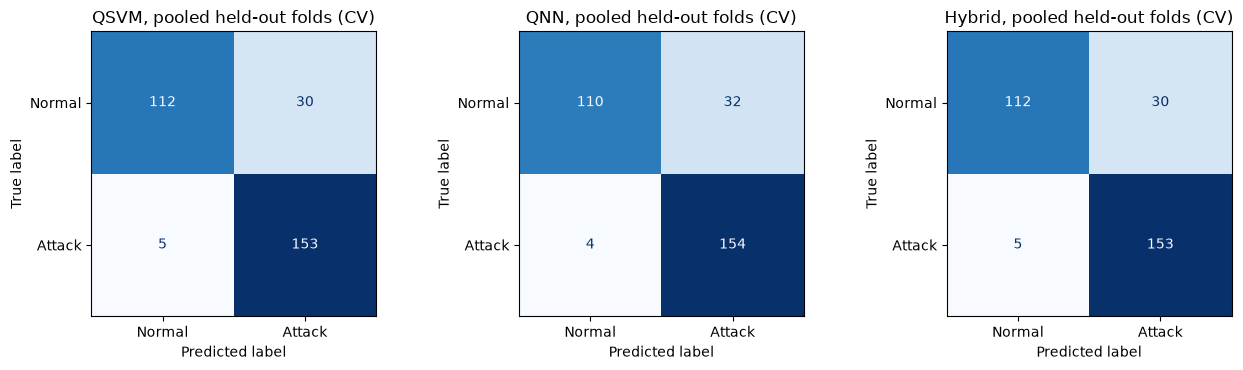

In [22]:
def run_cv(seed=SEED):
    g = train_part.groupby("label", group_keys=False)
    pool_c = g.sample(n=N_FIT_POOL // 2, random_state=seed + 1000)
    cv = train_part.drop(pool_c.index).sample(n=N_CV, random_state=seed).reset_index(drop=True)      # disjoint from the pool
    pr = prepare(pool_c, [cv], seed)
    F, X, y = pr["F"][0], pr["X"][0], cv["label"].to_numpy()
    oof = {m: np.zeros(len(y)) for m in MODELS_Q + MODELS_X}
    rows = []
    LIVE[0] = False
    for k, (a, b) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(X, y)):
        t0 = time.time()
        q1 = run_qsvm(X[a], y[a], X[b], seed + k)
        q2 = run_qnn(X[a], y[a], X[b], q1["bw"], seed + k, VQC_MAXITER)
        P = run_classical(X[a], y[a], X[b], F[a], F[b], seed + k)
        P.update({"QSVM": q1["p"], "QNN": q2["p"], "Hybrid": soft_vote(q1["p"], q2["p"])})
        for m in MODELS_Q + MODELS_X:
            oof[m][b] = P[m]
            rows.append({"fold": k, "model": m, **metrics(y[b], P[m])})
        print(f"fold {k}: {len(a)} train / {len(b)} held-out flows, bandwidth {q1['bw']:.2f}, C {q1['C']}, hybrid accuracy {metrics(y[b], P['Hybrid'])['accuracy']:.1f} ({time.time() - t0:.0f} s)", flush=True)
    LIVE[0] = True
    return pd.DataFrame(rows), oof, y, cv, pr

if RUN_CV:
    cv_df, OOF, y_cv, cv_sample, prep_cv = run_cv()
    meanB = cv_df.groupby("model")[METRIC_COLS + ["macro precision", "macro recall", "macro F1"]].mean().reindex(MODELS_Q + MODELS_X)
    stdB = cv_df.groupby("model")[METRIC_COLS].std(ddof=0).reindex(MODELS_Q + MODELS_X)
    print(f"\n{N_FOLDS}-fold stratified CV on {N_CV} flows of the training partition; mean +/- std over folds (attack = positive)")
    display(meanB[METRIC_COLS].round(1).astype(str) + " +/- " + stdB.round(1).astype(str))
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    for a_, m in zip(ax, ["QSVM", "QNN", "Hybrid"]):
        ConfusionMatrixDisplay(confusion_matrix(y_cv, OOF[m] >= .5), display_labels=["Normal", "Attack"]).plot(ax=a_, cmap="Blues", colorbar=False)
        a_.set_title(f"{m}, pooled held-out folds (CV)")
    plt.tight_layout(); plt.show()

## 10. Table 1 side by side, and which attacks each model catches

The first table puts the paper's five rows next to this notebook's two protocols. The second addresses the paper's qualitative claim that the QSVM is stronger on low-frequency attacks "such as U2R and **Probe**" and the QNN on large-scale ones "such as **DoS** and R2L": UNSW-NB15 has no U2R or R2L categories (those belong to KDD'99 / NSL-KDD), but it has **Reconnaissance** (the Probe analogue) and **DoS**, so the per-category detection rate (recall on attack flows of that category, pooled over the seeds of the official-split study) is compared for those two. Read it together with the last row, the share of *normal* flows classified as normal: a model that flags everything has a perfect detection rate for every attack and a poor specificity.

,paper accuracy,split accuracy,CV accuracy,paper F1,split F1,CV F1
model,,,,,,
SVM,89.2,73.7,88.0,88.0,75.0,89.7
ANN,90.5,71.9,88.0,89.4,73.7,89.7
QSVM,93.1,73.4,88.3,92.1,74.7,89.9
QNN,94.2,72.4,88.0,93.2,70.6,89.7
Hybrid,96.0,72.9,88.3,95.1,74.4,89.9


,paper precision,split precision,CV precision,paper recall,split recall,CV recall
model,,,,,,
SVM,88.4,60.2,83.3,87.6,99.7,97.5
ANN,89.7,58.6,83.3,89.1,99.5,97.5
QSVM,92.4,59.9,84.0,91.8,99.3,96.8
QNN,93.7,61.9,83.3,92.8,86.1,97.5
Hybrid,95.4,59.5,84.0,94.9,99.2,96.8


detection rate (%) per original category, official split, pooled over seeds (Normal row: share classified as normal)


,flows,QSVM,QNN,Hybrid,SVM,RF
category,,,,,,
Analysis,34,100.0,97.1,100.0,100.0,94.1
Backdoor,23,95.7,91.3,95.7,100.0,82.6
DoS,96,97.9,89.6,97.9,100.0,86.5
Exploits,401,99.0,89.8,98.8,99.5,88.5
Fuzzers,270,100.0,75.6,100.0,100.0,75.6
Generic,186,99.5,96.2,99.5,98.9,97.3
Reconnaissance,158,100.0,75.3,100.0,100.0,98.1
Shellcode,19,100.0,73.7,100.0,100.0,84.2
Worms,2,100.0,100.0,100.0,100.0,100.0


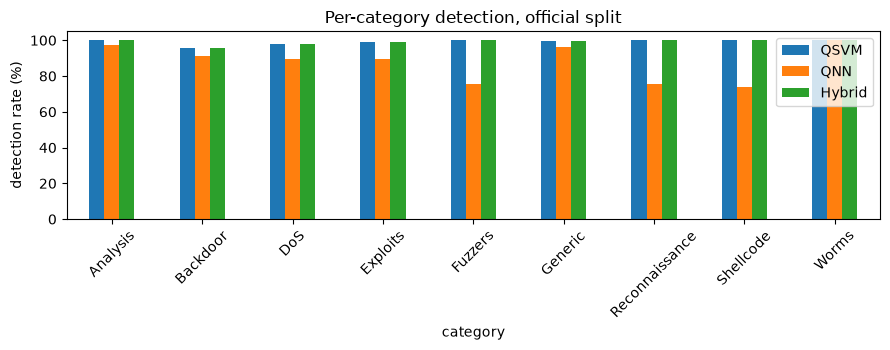

In [23]:
rows = []
for m in MODELS_Q:
    r = {"model": m}
    for j, c in enumerate(METRIC_COLS):
        r[f"paper {c}"] = PAPER[m][j]
        r[f"split {c}"] = round(meanA.loc[m, c], 1)
        if RUN_CV: r[f"CV {c}"] = round(meanB.loc[m, c], 1)
    rows.append(r)
table1 = pd.DataFrame(rows).set_index("model")
display(table1[[f"{p} {c}" for c in ["accuracy", "F1"] for p in ("paper", "split") + (("CV",) if RUN_CV else ())]])
display(table1[[f"{p} {c}" for c in ["precision", "recall"] for p in ("paper", "split") + (("CV",) if RUN_CV else ())]])

# per-category detection rate on the official split
yy = np.concatenate([r["y"] for r in RESA.values()]); cc = np.concatenate([r["cat"] for r in RESA.values()])
PP = {m: np.concatenate([r["P"][m] for r in RESA.values()]) for m in MODELS_Q + MODELS_X}
catrows = []
for a in ATTACKS:
    msk = cc == a
    if msk.sum() == 0: continue
    catrows.append({"category": a, "flows": int(msk.sum()), **{m: round(100 * (PP[m][msk] >= .5).mean(), 1) for m in ["QSVM", "QNN", "Hybrid", "SVM", "RF"]}})
catrows.append({"category": "Normal (specificity)", "flows": int((cc == "Normal").sum()), **{m: round(100 * (PP[m][cc == "Normal"] < .5).mean(), 1) for m in ["QSVM", "QNN", "Hybrid", "SVM", "RF"]}})
cat_df = pd.DataFrame(catrows).set_index("category")
print("detection rate (%) per original category, official split, pooled over seeds (Normal row: share classified as normal)")
display(cat_df)
cat_df.drop(index="Normal (specificity)")[["QSVM", "QNN", "Hybrid"]].plot.bar(figsize=(9, 3.6), rot=45, ylabel="detection rate (%)", title="Per-category detection, official split")
plt.tight_layout(); plt.show()

## 10b. Is the gap to the paper about quantum models or about the data?

The official-split scores of every model, quantum or classical, sit far below the paper's, while random folds of the training partition score much higher. This cell separates the two explanations with a **classical random forest and a large training set** (20,000 flows of the training partition, disjoint from the Min-Max/MI pool, many times more than a simulator can handle): its accuracy under 5-fold cross-validation inside the training partition is compared with its accuracy on the *whole* de-duplicated testing partition, once with the same 4 mutual-information features the qubits see and once with all encoded features. If the two numbers differ a lot, the gap is a property of the data split (training and testing partitions contain different traffic), not of the quantum models.

In [24]:
from sklearn.model_selection import cross_val_score
big = train_part.drop(pool.index).sample(n=20000, random_state=SEED)
pipe_ = prep["pipe"]; sel_ = prep["sel"]
Fb = np.clip(pipe_.transform(big[FEATS]), 0, 1); yb = big["label"].to_numpy()
Ft = np.clip(pipe_.transform(test_part[FEATS]), 0, 1); yt = test_part["label"].to_numpy()
ceil_rows = []
for name_, (A, T) in {"4 MI features (as the qubits)": (Fb[:, sel_], Ft[:, sel_]), "all %d encoded features" % Fb.shape[1]: (Fb, Ft)}.items():
    rf_ = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2)
    cv_acc = 100 * cross_val_score(rf_, A, yb, cv=5).mean()
    test_acc = 100 * accuracy_score(yt, rf_.fit(A, yb).predict(T))
    ceil_rows.append({"random forest, 20,000 training flows": name_, "5-fold CV accuracy inside the training partition": round(cv_acc, 1),
                      f"accuracy on the testing partition ({len(yt):,} flows)": round(test_acc, 1)})
CEIL = pd.DataFrame(ceil_rows).set_index("random forest, 20,000 training flows")
display(CEIL)

,5-fold CV accuracy inside the training partition,"accuracy on the testing partition (55,945 flows)"
"random forest, 20,000 training flows",,
4 MI features (as the qubits),90.3,82.0
all 58 encoded features,92.2,82.3


## 11. Claim ledger

In [25]:
TOL = 2.0                                           # points of accuracy / F1 (the project-wide tolerance)

def verdict(ours, paper, tol=TOL):
    if abs(ours - paper) <= tol: return "reproduced"
    return f"exceeded (+{ours - paper:.1f})" if ours > paper else f"not reached ({ours - paper:.1f})"

ledger = []
protocols = [("split", meanA)] + ([("CV", meanB)] if RUN_CV else [])
for tag, mean_ in protocols:
    for m in MODELS_Q:
        ledger.append(("C1/C2", f"Table 1 accuracy, {m} ({tag})", PAPER[m][0], round(mean_.loc[m, "accuracy"], 1), verdict(mean_.loc[m, "accuracy"], PAPER[m][0])))
        ledger.append(("C1/C2", f"Table 1 F1, {m} ({tag})", PAPER[m][3], round(mean_.loc[m, "F1"], 1), verdict(mean_.loc[m, "F1"], PAPER[m][3])))
    ledger.append(("C1", f"Table 1 precision, Hybrid ({tag})", PAPER["Hybrid"][1], round(mean_.loc["Hybrid", "precision"], 1), verdict(mean_.loc["Hybrid", "precision"], PAPER["Hybrid"][1])))
    ledger.append(("C1", f"Table 1 recall, Hybrid ({tag})", PAPER["Hybrid"][2], round(mean_.loc["Hybrid", "recall"], 1), verdict(mean_.loc["Hybrid", "recall"], PAPER["Hybrid"][2])))
    acc = mean_["accuracy"]
    chain = acc["SVM"] < acc["ANN"] < acc["QSVM"] < acc["QNN"] < acc["Hybrid"]
    ledger.append(("C3", f"ranking SVM < ANN < QSVM < QNN < Hybrid by accuracy ({tag})", "yes", "yes" if chain else "no: " + " ".join(f"{m} {acc[m]:.1f}" for m in MODELS_Q), "reproduced" if chain else "not reached"))
    hy = acc["Hybrid"] > max(acc["QSVM"], acc["QNN"])
    ledger.append(("C4", f"hybrid beats both standalone quantum models ({tag})", "yes", f"hybrid {acc['Hybrid']:.1f} vs {acc['QSVM']:.1f} / {acc['QNN']:.1f}", "reproduced" if hy else "not reached"))
    qc = min(acc["QSVM"], acc["QNN"]) > max(acc["SVM"], acc["ANN"])
    ledger.append(("C4", f"both quantum models beat the classical SVM and ANN on the same 4 inputs ({tag})", "yes", f"quantum {acc['QSVM']:.1f} / {acc['QNN']:.1f} vs classical {acc['SVM']:.1f} / {acc['ANN']:.1f}", "reproduced" if qc else "not reached"))
    hb = acc["Hybrid"] >= acc[MODELS_Q + MODELS_X].max()
    ledger.append(("C4", f"hybrid is the best model overall incl. RF and all-feature baselines ({tag})", "not claimed", f"best: {acc[MODELS_Q + MODELS_X].idxmax()} {acc[MODELS_Q + MODELS_X].max():.1f}", "extra check"))

ledger.append(("C5", "circuit: 4 qubits", 4, FM.num_qubits, "reproduced" if FM.num_qubits == 4 else "not reached"))
ledger.append(("C5", "circuit: 30 gate operations", 30, g_fm, "reproduced" if abs(g_fm - 30) <= 1 else f"not reached ({g_fm} after decomposition)"))
ledger.append(("C5", "circuit: depth 2 (read as 2 feature-map repetitions)", 2, 2, "reproduced (as repetitions; decomposed depth %d)" % d_fm))
rec_q, rec_n = cat_df.loc["Reconnaissance", "QSVM"], cat_df.loc["Reconnaissance", "QNN"]
dos_q, dos_n = cat_df.loc["DoS", "QSVM"], cat_df.loc["DoS", "QNN"]
ledger.append(("C6", "QSVM detects Reconnaissance (Probe) better than QNN", "yes", f"QSVM {rec_q} vs QNN {rec_n} (n = {cat_df.loc['Reconnaissance', 'flows']})", "reproduced" if rec_q > rec_n else "not reached"))
ledger.append(("C6", "QNN detects DoS better than QSVM", "yes", f"QNN {dos_n} vs QSVM {dos_q} (n = {cat_df.loc['DoS', 'flows']})", "reproduced" if dos_n > dos_q else "not reached"))
ledger.append(("C6", "U2R and R2L attacks", "see abstract", "categories absent from UNSW-NB15", "cannot be checked"))
if RUN_CV:
    sd = stdB.loc["Hybrid", "accuracy"]
    ledger.append(("C7", "five-fold CV is consistent (hybrid accuracy std over folds)", "'consistent' (no number)", f"std {sd:.1f} points over {N_FOLDS} folds", "cannot be checked (no number)"))
ledger.append(("-", "ultra-secure communication (QKD / PQC)", "title", "no experiment in the paper", "cannot be checked"))
ledger_df = pd.DataFrame(ledger, columns=["claim", "what", "paper", "notebook", "verdict"])
pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 200)
display(ledger_df)
print(ledger_df["verdict"].str.replace(r"\s*\(.*$", "", regex=True).value_counts().to_dict())

,claim,what,paper,notebook,verdict
0,C1/C2,"Table 1 accuracy, SVM (split)",89.2,73.7,not reached (-15.5)
1,C1/C2,"Table 1 F1, SVM (split)",88.0,75.0,not reached (-13.0)
2,C1/C2,"Table 1 accuracy, ANN (split)",90.5,71.9,not reached (-18.6)
3,C1/C2,"Table 1 F1, ANN (split)",89.4,73.7,not reached (-15.7)
4,C1/C2,"Table 1 accuracy, QSVM (split)",93.1,73.4,not reached (-19.7)
5,C1/C2,"Table 1 F1, QSVM (split)",92.1,74.7,not reached (-17.4)
6,C1/C2,"Table 1 accuracy, QNN (split)",94.2,72.4,not reached (-21.8)
7,C1/C2,"Table 1 F1, QNN (split)",93.2,70.6,not reached (-22.6)
8,C1/C2,"Table 1 accuracy, Hybrid (split)",96.0,72.9,not reached (-23.1)
9,C1/C2,"Table 1 F1, Hybrid (split)",95.1,74.4,not reached (-20.7)


{'not reached': 27, 'reproduced': 7, 'cannot be checked': 3, 'extra check': 2, 'exceeded': 1}


## Reading the paper critically

Points to raise with students. Numbers quoted as "in the saved run" come from the `FAST_MODE = False` run that produced the outputs above; yours will differ by a few points.

- **The headline numbers are not tied to a protocol.** The paper describes both the predefined 175,341 / 82,332 split and five-fold cross-validation, and Table 1 does not say which one produced it. Sections 8 and 9 show why that matters: in the saved run every model scores about 72-74 % accuracy on the official testing partition but about 88 % in random folds of the training partition. Neither protocol comes close to the paper's 96.0 % for the hybrid.
- **The gap is the data split, not the qubit budget.** Section 10b trains a random forest on 20,000 flows (far more than a simulator can handle): with the same 4 features it reaches 90.3 % in cross-validation inside the training partition but 82.0 % on the testing partition, and with all 58 encoded features 92.2 % versus 82.3 %. The official training and testing partitions contain different traffic, so any model, quantum or classical, loses 8-10 points between the two, while a 4-feature forest stays within about 2 points of an all-feature one under both protocols. A 96 % result on the official testing partition with 4 features is therefore very unlikely, and the paper does not say how its number was obtained.
- **Min-Max on heavy tails flattens a qubit.** `sbytes`, the top mutual-information feature, spans about six orders of magnitude (28 bytes to 13 million), so after the paper's plain Min-Max scaling almost every flow sits at about 0 (see the first-two-features scatter plot) and one qubit effectively carries a constant. The other three selected features (`sttl`, `dttl`, `ct_state_ttl`) take only 4-5 distinct values: in the saved run 300 training flows occupy only 167 distinct positions of the 4-feature space, so the models are close to a lookup table. This is also why several models give *identical* rows in the cross-validation table. Set `LOG_TRANSFORM = True` (exercise 7) to see how much a log transform changes the picture.
- **The hybrid is not better than its better member here.** A soft vote can only beat both members when their errors differ. In the saved run the hybrid scores 72.9 % on the official split against 73.4 % (QSVM) and 72.4 % (QNN), well inside the seed spread (standard deviations of 0.9 to 2.8 points), and 88.3 % against 88.3 % / 88.0 % in cross-validation. The paper's progression SVM < ANN < QSVM < QNN < Hybrid, with every step 1-3 points, is not reproduced by these runs; the five models are statistically indistinguishable on 4 features and a few hundred flows.
- **The classical baselines are not baselines.** The SVM (89.2 %) and ANN (90.5 %) rows are cited from two earlier papers by one of the authors, on EEG emotion recognition and hearing-loss detection (refs. 16-17), not computed on UNSW-NB15. Table 1 therefore compares models run on UNSW-NB15 with unrelated numbers. Here the classical models run on the same inputs; in cross-validation they land within a point of the quantum models.
- **Detection rates reward alarm-everything classifiers.** In the per-category table the QSVM catches 98-100 % of nearly every attack category, but it flags 44 % of normal flows (specificity 56 %), as do the classical SVM and the hybrid; the random forest is more selective (specificity 72 %). The paper's claim that QSVM is better on Probe-like and QNN on DoS-like attacks (Reconnaissance versus DoS here) can only be judged together with the false alarms, and the paper reports neither per-category nor per-class numbers.
- **Duplicates and sizes.** The paper removes duplicates but quotes the un-deduplicated partition sizes, and its description of the data ("about 2.5 million records with 49 features") is that of the raw capture, not of the 257,673-record partitions it uses. Whether duplicates are removed changes the class mix of UNSW-NB15 drastically (most of "Generic" is duplicated), so reported scores are not comparable across papers without it.
- **Attack types that do not exist in the data.** The abstract motivates the QSVM with U2R and Probe attacks and the QNN with DoS and R2L, but UNSW-NB15 has neither U2R nor R2L (these are KDD'99 / NSL-KDD categories), so part of the "complementary strengths" argument for the ensemble cannot have been tested on this data.
- **Table 1 reports no uncertainty.** No standard deviations, seeds or confidence intervals are given; the test sample here (1,000 flows) already has a binomial standard error of about 1.4 points, and the seed-to-seed standard deviation of the QNN is 2.8 points.
- **Simulation is not speed-up.** Everything is computed by classical simulators on 4 qubits; nothing here can show a quantum advantage. The paper itself says it is "not yet capable of addressing real-time constraints, energy efficiency, or deployment on physical IoT devices".
- **The title promises more than the paper delivers.** "Ultra-secure communication" (QKD, post-quantum cryptography) appears only in the related-work section; there is no experiment on it.
- **Sample size.** The quantum models see a few hundred flows. The paper's models, if trained on the 175,341 flows, would not have been simulable with exact kernels (a 175,341 x 175,341 kernel matrix).

## Exercises

1. Set `N_QUBITS = 6` or `8` and compare the classical baselines on the 6-8 selected features with the quantum models. How much of the gap to the all-feature baselines closes, and what happens to the simulation time?
2. Set `DROP_DUPLICATES = False` and rerun. How do the class mix of the test sample and the scores of every model change?
3. Replace the mutual-information selection by `PCA(n_components=4)` (as in the sibling notebooks) and compare the official-split scores. Which features carried the distribution shift?
4. Change `soft_vote(..., w=0.5)` to weights 0.3 / 0.7 and 0.7 / 0.3. Does any weighting make the hybrid better than the better of its two members?
5. Replace `entanglement="linear"` by `"full"` or by `reps=1` and re-draw the circuit. How do the gate count and the kernel block structure (Section 4) change, and does the validation F1 move?
6. Use only the two categories Reconnaissance and DoS: train a QSVM and a QNN to separate each from Normal and check the paper's "complementary strengths" claim with a proper per-task experiment.
7. Set `LOG_TRANSFORM = True` (`log1p` before Min-Max) and rerun. How does the mutual-information ranking change, how many distinct positions do the training flows occupy, and do the official-split scores move?

In [26]:
elapsed = (time.time() - NOTEBOOK_T0) / 60
print(f"FAST_MODE = {FAST_MODE}, seeds = {SEEDS}, N_TRAIN = {N_TRAIN}, N_TEST = {N_TEST}, VQC_MAXITER = {VQC_MAXITER}, CV = {N_FOLDS} folds on {N_CV} flows")
print(f"whole notebook: {elapsed:.1f} min wall clock")

FAST_MODE = False, seeds = [42, 43, 44], N_TRAIN = 300, N_TEST = 1000, VQC_MAXITER = 60, CV = 5 folds on 300 flows
whole notebook: 69.0 min wall clock
